# Notebook 3: RCA Dataset Modeling, Robustness, and Pareto Analysis

## Purpose

This notebook extends the baseline supplementary cementitious material concrete analysis by integrating an RCA-specific dataset. It provides an end-to-end analysis of recycled aggregate concrete compressive strength while addressing the data-quality, validation, feature-redundancy, sustainability, and Pareto-frontier concerns identified during the repository review.

The selected dataset is:

**Awoyera, Paul (2025), “Mechanical Properties of Recycled Aggregate Concrete,” Mendeley Data, Version 1. DOI: `10.17632/2pxdbh6vx7.1`.**

The analysis:

1. Loads and standardizes the RCA dataset.
2. Preserves source-row identifiers for auditing.
3. Applies documented corrections only when supplied in a correction file.
4. Detects and quarantines physically implausible values rather than silently changing them.
5. Audits whether the reported aggregate-cement ratio is consistent with the material quantities.
6. Compares compact, original, and engineered feature sets.
7. Uses group-aware cross-validation for model comparison and hyperparameter tuning.
8. Evaluates the selected model on one untouched grouped hold-out set.
9. performs repeated nested grouped validation to estimate model-development variability.
10. Calculates a simplified emissions proxy under low, central, and high literature scenarios.
11. Generates Pareto candidates using out-of-fold predictions across the full cleaned dataset.
12. Measures whether Pareto candidates remain stable across emissions-factor scenarios.
13. Reports subgroup errors, limitations, and a cautious final synthesis.

## Interpretation limits

- This notebook estimates compressive strength from a small compiled dataset.
- It does not establish causal material effects.
- The sustainability calculation is a simplified emissions proxy, not a complete life-cycle assessment.
- Pareto candidates are nondominated observed mixtures within this dataset, not globally optimized concrete recipes.
- External validation on an independent RCA dataset is still needed for stronger generalization claims.

## 1. Required repository files

Place the RCA dataset in the repository `data/` folder using either the recommended name or the original Mendeley filename:

```text
data/rca_awoyera_2025_mechanical_properties.xlsx
data/RCA for New model.xlsx
```

Optional supporting files:

```text
data/rca_data_corrections.csv
data/rca_sustainability_factor_scenarios.csv
```

The corrections file must contain:

```text
source_row_number,column,corrected_value,reason,source_evidence
```

Corrections are applied only when a documented file is present. Otherwise, physically implausible rows are saved for manual review and excluded from modeling.

In [1]:
# Installs dependencies when running in Google Colab.
# If these packages are already installed, this cell will finish quickly.
import os
import re
import sys
import json
import hashlib
import platform
import subprocess
import warnings
from pathlib import Path

try:
    import openpyxl  # needed for .xlsx files
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "openpyxl"]
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    GridSearchCV,
    cross_validate,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.inspection import permutation_importance

# Cleans the output by hiding old code alerts
warnings.filterwarnings("ignore", category=FutureWarning)

# Ensures repeatability
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Referenced multiple times in the code to differentiate outputs and figures
# from other datasets
OUTPUT_PREFIX = "rca"

# Increase for higher resolution images
FIG_DPI = 300

# Number of outer repeated grouped validation splits.
# Ten is suitable for a standard Colab run. Increase for the final frozen run.
# Used in Section 12 of the notebook
N_REPEATED_GROUP_SPLITS = int(
    os.environ.get("RCA_NESTED_REPEATS", "30")
)

# Flagged rows are excluded after being saved for manual review.
# No value is silently corrected.
FLAGGED_ROW_POLICY = "exclude"

## 2. Project paths

Repository mode is the default. Google Drive remains available as an optional workflow.

In [2]:
# ============================================================
# Project configuration
# ============================================================
# Use variable if using non-repo directory
# ECO_CONCRETE_DRIVE_BASE = (directory link)
RUN_MODE = os.environ.get(
    "ECO_CONCRETE_RUN_MODE",
    "repo",
).strip().lower()

# Mounts drive and establishes dataset
if RUN_MODE == "drive":
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError(
            "RUN_MODE='drive' requires Google Colab."
        ) from exc

    drive.mount("/content/drive")

    BASE_DIR = Path(
        os.environ.get(
            "ECO_CONCRETE_DRIVE_BASE",
            "/content/drive/MyDrive/ProjectName",
        )
    )

# Repo option makes the notebook runnable from GitHub
# Make sure to add data folder to local notebook files
elif RUN_MODE == "repo":
    cwd = Path.cwd()
    BASE_DIR = cwd.parent if cwd.name == "notebooks" else cwd

else:
    raise ValueError(
        "RUN_MODE must be either 'repo' or 'drive'."
    )

# Output folders
# DATA_DIR from the previous code is defined for referencing
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
OUT_DIR = BASE_DIR / "outputs"

# Checks and creates missing folders, if applicable
# If all folders exist, code is ignored
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Displays set-up details for verification
print("RUN_MODE:", RUN_MODE)
print("BASE_DIR:", BASE_DIR)
print("DATA_DIR:", DATA_DIR)
print("FIG_DIR:", FIG_DIR)
print("OUT_DIR:", OUT_DIR)

RUN_MODE: repo
BASE_DIR: /content
DATA_DIR: /content/data
FIG_DIR: /content/figures
OUT_DIR: /content/outputs


## 3. Load and standardize the selected RCA dataset

The loader accepts `.xlsx`, `.xls`, or `.csv`. When an Excel workbook contains multiple sheets, the sheet with the strongest match to the expected RCA schema is selected.

In [3]:
# Defines citation elements of the uploaded dataset
RCA_DATASET_DOI = "10.17632/2pxdbh6vx7.1"
RCA_DATASET_TITLE = (
    "Mechanical Properties of Recycled Aggregate Concrete"
)
RCA_DATASET_AUTHOR = "Paul Awoyera"
RCA_DATASET_YEAR = "2025"

# Selects dataset off of common names
# Helps differentiate between multiple uploaded datasets
RCA_DATASET_CANDIDATES = [
    "rca_awoyera_2025_mechanical_properties.xlsx",
    "RCA for New model.xlsx",
    "rca_for_new_model.xlsx",
    "mechanical_properties_recycled_aggregate_concrete.xlsx",
    "rca_awoyera_2025_mechanical_properties.csv",
]

# Checks if a valid candidate exists; if not, print error message
for filename in RCA_DATASET_CANDIDATES:
    candidate = DATA_DIR / filename
    if candidate.exists():
        rca_path = candidate
        break
else:
    available = sorted(path.name for path in DATA_DIR.glob("*"))

    message = [
        "Could not find the selected RCA dataset in data/.",
        "",
        (
            f"Dataset: {RCA_DATASET_AUTHOR} ({RCA_DATASET_YEAR}), "
            f"'{RCA_DATASET_TITLE}', DOI {RCA_DATASET_DOI}."
        ),
        (
            "Save it as "
            "data/rca_awoyera_2025_mechanical_properties.xlsx "
            "or keep the original filename 'RCA for New model.xlsx'."
        ),
        "",
        "Current files in data/:",
        *[f"- {item}" for item in available],
    ]

    raise FileNotFoundError("\n".join(message))

# If dataset does exist, print the selected dataset
# Use this as a final check for the correct dataset
print("RCA dataset file:", rca_path)

RCA dataset file: /content/data/rca_awoyera_2025_mechanical_properties.xlsx


In [4]:
# Normalizes the dataset columns to improve code reliability
def normalize_col(name):
    name = str(name).strip().lower()
    name = name.replace("²", "2").replace("³", "3")
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return re.sub(r"_+", "_", name).strip("_")

# Specifically searches for exact target and feature columns
# Returns the normalized columns before continuing
def canonical_name(name):
    normalized = normalize_col(name)

    if normalized in {
        "w_c",
        "wc",
        "w_c_ratio",
        "water_cement_ratio",
        "water_to_cement_ratio",
    }:
        return "water_cement_ratio"

    if (
        "water" in normalized
        and "cement" in normalized
        and "ratio" in normalized
    ):
        return "water_cement_ratio"

    if normalized in {
        "a_c",
        "ac",
        "aggregate_cement_ratio",
        "aggregate_to_cement_ratio",
    }:
        return "aggregate_cement_ratio"

    if (
        "aggregate" in normalized
        and "cement" in normalized
        and "ratio" in normalized
    ):
        return "aggregate_cement_ratio"

    if normalized in {
        "water",
        "water_kg_m3",
        "water_kg_m_3",
    }:
        return "water"

    if normalized in {
        "cement",
        "cement_kg_m3",
        "cement_kg_m_3",
    }:
        return "cement"

    if normalized in {
        "nfa",
        "natural_fine_aggregate",
        "natural_fine_aggregate_kg_m3",
    }:
        return "natural_fine_aggregate"

    if (
        "natural" in normalized
        and "fine" in normalized
        and "aggregate" in normalized
    ):
        return "natural_fine_aggregate"

    if normalized in {
        "nca",
        "natural_coarse_aggregate",
        "natural_coarse_aggregate_kg_m3",
    }:
        return "natural_coarse_aggregate"

    if (
        "natural" in normalized
        and "coarse" in normalized
        and "aggregate" in normalized
    ):
        return "natural_coarse_aggregate"

    if normalized in {
        "rca",
        "recycled_coarse_aggregate",
        "recycled_coarse_aggregate_kg_m3",
    }:
        return "recycled_coarse_aggregate"

    if (
        "recycled" in normalized
        and "coarse" in normalized
        and "aggregate" in normalized
    ):
        return "recycled_coarse_aggregate"

    if normalized in {
        "rfa",
        "recycled_fine_aggregate",
        "recycled_fine_aggregate_kg_m3",
    }:
        return "recycled_fine_aggregate"

    if (
        "recycled" in normalized
        and "fine" in normalized
        and "aggregate" in normalized
    ):
        return "recycled_fine_aggregate"

    if "compressive" in normalized and "strength" in normalized:
        return "compressive_strength_mpa"

    if (
        "split" in normalized
        and "tensile" in normalized
        and "strength" in normalized
    ):
        return "split_tensile_strength_mpa"

    if "tensile" in normalized and "strength" in normalized:
        return "split_tensile_strength_mpa"

    if "flexural" in normalized and "strength" in normalized:
        return "flexural_strength_mpa"

    if "modulus" in normalized and "elastic" in normalized:
        return "modulus_of_elasticity_mpa"

    return normalized

# Removes identical or redundant columns from dataset
# Prevents calculation errors and cleans up the dataset
def collapse_duplicate_columns(frame):
    if not frame.columns.duplicated().any():
        return frame
    combined = pd.DataFrame(index=frame.index)
    for column in pd.unique(frame.columns):
        subset = frame.loc[:, frame.columns == column]
        combined[column] = subset.bfill(axis=1).iloc[:, 0]
    return combined

# Checks the dataset's format to the code's expectations
# Prevents schema drift or structure change
def schema_match_score(frame):
    temporary = frame.copy()
    temporary.columns = [
        canonical_name(column)
        for column in temporary.columns
    ]

    expected = {
        "water_cement_ratio",
        "aggregate_cement_ratio",
        "water",
        "cement",
        "natural_fine_aggregate",
        "natural_coarse_aggregate",
        "recycled_coarse_aggregate",
        "recycled_fine_aggregate",
        "compressive_strength_mpa",
    }

    return len(set(temporary.columns).intersection(expected))

# Checks the file type and selects the best sheet after cleaning the data
# Puts into pandas DataFrame
def load_rca_table(path):
    suffix = path.suffix.lower()
    if suffix == ".csv":
        raw = pd.read_csv(path)
        selected_sheet = "csv"
    elif suffix in {".xlsx", ".xls"}:
        workbook = pd.ExcelFile(path)
        sheet_options = []
        for sheet_name in workbook.sheet_names:
            sheet = pd.read_excel(
                path,
                sheet_name=sheet_name,
            )

            # Preserves actual Excel rows before running dropna()
            sheet["source_row_number"] = sheet.index + 2

            sheet = (
                sheet.dropna(how="all")
                .dropna(axis=1, how="all")
            )
            if len(sheet) > 0:
                sheet_options.append(
                    (
                        sheet_name,
                        schema_match_score(sheet),
                        sheet,
                    )
)
        if not sheet_options:
            raise ValueError("The Excel file contains no nonempty sheets.")
        selected_sheet, score, raw = max(sheet_options, key=lambda item: item[1],)
        print(f"Selected sheet: {selected_sheet}; "f"schema score: {score}")
    else:
        raise ValueError(f"Unsupported file type: {suffix}")

    # Cleans pandas DataFrame before returning it
    raw = raw.copy()
    raw.columns = [canonical_name(column) for column in raw.columns ]
    raw = collapse_duplicate_columns(raw)
    raw = raw.dropna(how="all")
    raw["source_file"] = path.name
    raw["source_sheet"] = selected_sheet
    return raw

# Displays current cleaned data table for verification
raw_df = load_rca_table(rca_path)
print("Raw shape:", raw_df.shape)
display(raw_df.head())

Selected sheet: Sheet1; schema score: 9
Raw shape: (112, 15)


,water_cement_ratio,aggregate_cement_ratio,water,cement,natural_fine_aggregate,natural_coarse_aggregate,recycled_coarse_aggregate,recycled_fine_aggregate,compressive_strength_mpa,split_tensile_strength_mpa,flexural_strength_mpa,modulus_of_elasticity_mpa,source_row_number,source_file,source_sheet
0,0.4,4.25,120.0,300.0,763.0,1366.000000,340.000000,214.333333,34.8,4.0,4.2,33288.0,2,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
1,0.4,4.25,120.0,300.0,763.0,1025.000000,290.000000,549.403333,33.2,3.8,4.1,31684.0,3,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
2,0.4,4.25,120.0,300.0,763.0,683.000000,570.000000,202.450000,32.1,3.5,4.0,28510.0,4,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
3,0.4,4.25,120.0,300.0,763.0,823.333333,1150.000000,198.403333,29.3,3.0,3.9,22215.0,5,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
4,0.4,4.25,140.0,350.0,728.0,1304.000000,361.666667,214.333333,41.2,4.3,4.5,37800.0,6,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1


**Result Interpretation:** The code states that the number of rows in the original dataset is 112, and the number of columns is 15. This is before any rows are removed.

## 4. Apply documented corrections, then audit data quality

The current dataset previously produced a recycled coarse aggregate value of `11,027`, which is physically implausible under a `kg/m³` interpretation. This notebook does not guess that the value should be `1,102.7`. Instead, it:

1. Applies a correction only when a documented correction file is supplied.
2. Saves every flagged row for manual review.
3. Suggests possible review when errors in a mixture can be confirmed with further research.
4. Excludes unresolved flagged rows from modeling.

In [5]:
# Defines columns into categories
# Uses listed names as machine learning inputs
TARGET_COL = "compressive_strength_mpa"

ORIGINAL_FEATURES = [
    "water_cement_ratio",
    "aggregate_cement_ratio",
    "water",
    "cement",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_coarse_aggregate",
    "recycled_fine_aggregate",
]

OPTIONAL_OUTPUTS = [
    "split_tensile_strength_mpa",
    "flexural_strength_mpa",
    "modulus_of_elasticity_mpa",
]

# Verifies that all columns are present in dataset before continuing
required_columns = ORIGINAL_FEATURES + [TARGET_COL]

missing_required = [
    column
    for column in required_columns
    if column not in raw_df.columns
]

if missing_required:
    raise KeyError(
        "Missing required columns after normalization: "
        f"{missing_required}. "
        f"Available columns: {raw_df.columns.tolist()}"
    )

# Retains additional columns not required for concrete compressive strength predictions
available_optional_outputs = [
    column
    for column in OPTIONAL_OUTPUTS
    if column in raw_df.columns
]

model_df = raw_df[
    required_columns
    + available_optional_outputs
    + [
        "source_row_number",
        "source_file",
        "source_sheet",
    ]
].copy()

# Validation for current rows
print("Rows entering audit:", len(model_df))

# Converts and/or coerces values into numerics
for column in required_columns + available_optional_outputs:
    model_df[column] = pd.to_numeric(
        model_df[column],
        errors="coerce",
    )

# ------------------------------------------------------------
# Optional documented corrections
# ------------------------------------------------------------
# Ensure the file is correctly named for corrections to be implemented
# Use after manual review of the dataset
corrections_path = DATA_DIR / "rca_data_corrections.csv"
correction_log = []

# Checks if CSV exists, then confirms all the required columns exist
# If they don't, then raise an error message
# Same process is done with rows
if corrections_path.exists():
    corrections_df = pd.read_csv(corrections_path)

    required_correction_columns = {
        "source_row_number",
        "column",
        "corrected_value",
        "reason",
        "source_evidence",
        "remove",
    }

    missing_correction_columns = (
        required_correction_columns
        - set(corrections_df.columns)
    )

    if missing_correction_columns:
        raise ValueError(
            "Correction file is missing columns: "
            f"{sorted(missing_correction_columns)}"
        )

    for _, correction in corrections_df.iterrows():
        row_number = int(correction["source_row_number"])
        column = str(correction["column"]).strip()

        if column not in required_columns:
            raise ValueError(
                f"Correction refers to unknown column: {column}"
            )

        row_mask = (
            model_df["source_row_number"]
            == row_number
        )

        if row_mask.sum() != 1:
            raise ValueError(
                "Correction row could not be uniquely matched: "
                f"source_row_number={row_number}"
            )

        # Check whether the row is marked for removal
        # Used for mixture rows that cannot have the values verified

        remove_value = (
            str(correction["remove"])
            .strip()
            .lower()
        )

        # Skip correction if row is marked "True" for removal
        if remove_value == "true":
            print(
                f"Skipping correction for source_row_number="
                f"{row_number} because remove=True."
            )
            continue

        original_value = model_df.loc[
            row_mask,
            column,
        ].iloc[0]

        corrected_value = float(
            correction["corrected_value"]
        )

        model_df.loc[
            row_mask,
            column,
        ] = corrected_value

        correction_log.append(
            {
                "source_row_number": row_number,
                "column": column,
                "original_value": original_value,
                "corrected_value": corrected_value,
                "reason": correction["reason"],
                "source_evidence": correction[
                    "source_evidence"
                ],
            }
        )

# Removes rows marked as "True" for removal
rows_to_remove = (
    corrections_df.loc[
        corrections_df["remove"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("true"),
        "source_row_number",
    ]
    .astype(int)
    .tolist()
)

print("Rows marked for removal:", rows_to_remove)

model_df = model_df[
    ~model_df["source_row_number"].isin(rows_to_remove)
].copy()

# Saves and applies the corrections to the current dataset
# Makes recording corrections simpler during review
correction_log_df = pd.DataFrame(correction_log)
correction_log_path = (
    OUT_DIR / "rca_documented_correction_log.csv"
)
correction_log_df.to_csv(
    correction_log_path,
    index=False,
)

print(
    "Documented corrections applied:",
    len(correction_log_df),
)

if len(correction_log_df) > 0:
    display(
        correction_log_df[
            [
                "source_row_number",
                "column",
                "original_value",
                "corrected_value",
                "reason",
                "source_evidence",
            ]
        ])

else:
    print("No documented corrections were applied.")

print("Saved:", correction_log_path)

# Check final dataset shape after corrections and removals
print("Final model_df shape:", model_df.shape)

Rows entering audit: 112
Skipping correction for source_row_number=51 because remove=True.
Rows marked for removal: [51]
Documented corrections applied: 0
No documented corrections were applied.
Saved: /content/outputs/rca_documented_correction_log.csv
Final model_df shape: (111, 15)


**Result Interpretation:** No corrections are applied to the original dataset. A total of 111 rows and 15 columns still exist after manual review and corrections of the data. If the total rows do not match the raw shape listed in Section 3, rerun the code from Section 3 of the code.

In [6]:
# ============================================================
# Missing, finite, and physically plausible value audit setup
# ============================================================
# Code notifies the user of missing values or incomplete rows, then deletes them
# Important for manual fixes and helps run the code regardless of errors
print(
    "Missing or nonnumeric required values before filtering:"
)
display(
    model_df[required_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)

model_df["total_aggregate_raw"] = (
    model_df["natural_fine_aggregate"]
    + model_df["natural_coarse_aggregate"]
    + model_df["recycled_fine_aggregate"]
    + model_df["recycled_coarse_aggregate"]
)

# ============================================================
# Nonnegative and positive value check
# ============================================================
# Checks for impossible values in the dataset
# Removes them if they exist
nonnegative_cols = ORIGINAL_FEATURES
positive_cols = ["water_cement_ratio", "aggregate_cement_ratio", "water", "cement", TARGET_COL]
invalid_rows = (
    (model_df[nonnegative_cols] < 0).any(axis=1)
    | (model_df[positive_cols] <= 0).any(axis=1)
    | (~np.isfinite(model_df[required_columns]).all(axis=1))
)
print("Rows removed for impossible values:", int(invalid_rows.sum()))
model_df = model_df.loc[~invalid_rows].copy()

# Checks values for magnitude
# Dissplays the mixture with the larger magnitude of recycled coarse aggregate
max_rca_index = model_df["recycled_coarse_aggregate"].idxmax()
display(model_df.loc[[max_rca_index]])

# ============================================================
# Plausible and missing values check
# ============================================================
# Code defines the plausible ranges for each feature
# Ranges can be edited for more/less variation between mixtures
PLAUSIBILITY_LIMITS = {
    "water_cement_ratio": (0.20, 1.20),
    "aggregate_cement_ratio": (0.50, 12.00),
    "water": (50.0, 500.0),
    "cement": (100.0, 1000.0),
    "natural_fine_aggregate": (0.0, 2500.0),
    "natural_coarse_aggregate": (0.0, 2500.0),
    "recycled_fine_aggregate": (0.0, 2500.0),
    "recycled_coarse_aggregate": (0.0, 2500.0),
    "compressive_strength_mpa": (1.0, 150.0),
    "total_aggregate_raw": (300.0, 4000.0),
}

# Checks if the column being audited falls outside its defined range
# If so, the column is classified as "invalid"
audit_df = model_df.copy()
audit_df["quality_flags"] = ""

for column, (lower, upper) in PLAUSIBILITY_LIMITS.items():
    invalid = (
        audit_df[column].isna()
        | ~np.isfinite(audit_df[column])
        | (audit_df[column] < lower)
        | (audit_df[column] > upper)
    )

    audit_df.loc[
        invalid,
        "quality_flags",
    ] += (
        f"{column}_outside_"
        f"[{lower},{upper}];"
    )

# Initializes an empty list for inputting invalid feature columns
audit_df["suggested_manual_review"] = ""

# Code checks aggregate values by applying plausability ranges
aggregate_columns = [
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_fine_aggregate",
    "recycled_coarse_aggregate",
]

for column in aggregate_columns:
    decimal_shift_candidate = (
        (audit_df[column] > 2500.0)
        & (audit_df[column] / 10.0 <= 2500.0)
    )

    audit_df.loc[
        decimal_shift_candidate,
        "suggested_manual_review",
    ] += (
        f"Check whether {column} has a misplaced decimal; "
        f"candidate value is current_value/10;"
    )

# Separates flagged rows and saves to a CSV for manual review
flagged_rows = audit_df[
    audit_df["quality_flags"].str.len() > 0
].copy()

flagged_path = (
    OUT_DIR / "rca_flagged_rows_for_manual_review.csv"
)
flagged_rows.to_csv(
    flagged_path,
    index=False,
)

# Shows and prints flagged rows if they exist
print("Flagged rows:", len(flagged_rows))
print("Saved:", flagged_path)

if len(flagged_rows) > 0:
    display(
        flagged_rows[
            [
                "source_row_number",
                *required_columns,
                "total_aggregate_raw",
                "quality_flags",
                "suggested_manual_review",
            ]
        ]
    )

# Variable is set at the beginning of the notebook
# The present notebook runs FLAGGED_ROW_POLICY = "exclude" and saves the
# excluded rows for manual review
if FLAGGED_ROW_POLICY == "exclude":
    model_df = audit_df[
        audit_df["quality_flags"].str.len() == 0
    ].copy()

elif FLAGGED_ROW_POLICY == "error":
    if len(flagged_rows) > 0:
        raise ValueError(
            "Physically implausible rows were detected. "
            "Review the saved audit before continuing."
        )
    model_df = audit_df.copy()

else:
    raise ValueError(
        "FLAGGED_ROW_POLICY must be 'exclude' or 'error'."
    )

# Code keeps one version with duplicate rows and one without duplicates
# Model version with duplicate rows
model_df_with_duplicates = model_df.copy()

# Checks for exact duplicate mixtures in dataset
exact_duplicate_count = int(
    model_df.duplicated(
        subset=required_columns,
        keep=False,
    ).sum()
)

print(
    "Rows involved in exact duplicate feature/target records:",
    exact_duplicate_count,
)

# Model version without duplicate rows
model_df_without_duplicates = (
    model_df
    .drop_duplicates(
        subset=required_columns,
    )
    .reset_index(drop=True)
)

print(
    "Rows with duplicates:",
    len(model_df_with_duplicates),
)

print(
    "Rows without duplicates:",
    len(model_df_without_duplicates),
)

print(
    "Duplicate records removed:",
    len(model_df_with_duplicates)
    - len(model_df_without_duplicates),
)

# Creates a backup of no-duplicate model as the default model_df
model_df = model_df_without_duplicates.copy()

# Displays the prepared rows for the user
print("Prepared rows after audit:", len(model_df))

Missing or nonnumeric required values before filtering:


,missing_count
water_cement_ratio,0
aggregate_cement_ratio,0
water,0
cement,0
natural_fine_aggregate,0
natural_coarse_aggregate,0
recycled_coarse_aggregate,0
recycled_fine_aggregate,0
compressive_strength_mpa,0


Rows removed for impossible values: 0


,water_cement_ratio,aggregate_cement_ratio,water,cement,natural_fine_aggregate,natural_coarse_aggregate,recycled_coarse_aggregate,recycled_fine_aggregate,compressive_strength_mpa,split_tensile_strength_mpa,flexural_strength_mpa,modulus_of_elasticity_mpa,source_row_number,source_file,source_sheet,total_aggregate_raw
46,0.49,4.25,211.0,398.0,614.0,278.333333,1193.0,204.736667,44.26,3.651791,5.07,40800.0,48,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1,2290.07


Flagged rows: 0
Saved: /content/outputs/rca_flagged_rows_for_manual_review.csv
Rows involved in exact duplicate feature/target records: 8
Rows with duplicates: 111
Rows without duplicates: 104
Duplicate records removed: 7
Prepared rows after audit: 104


**Result Interpretation:** With 8 duplicate records and 111 rows, the final number of prepared rows indicates that 7 duplicate rows have been removed from the dataset.

Note that the first instance of a row is counted as a duplicate. Since all the duplicates are exact copies of each other (source rows 106-113) and it cannot be confirmed if each duplicate is a separate, individual measurement, it is not reasonable to give one record eight times the statistical weight compared to every other recorded mixture. Therefore, future code will not use duplicates as a part of model training. However, a copy of the dataset with the duplicates is retained if needed.

Also note that since the number of rows is small, the grouped split changes a very small number of repeated mixtures. This information will be expanded upon in Section 12 of the present code.


## 5. Audit the aggregate-cement ratio and units

The reported aggregate-cement ratio is compared against several calculations derived from the material columns. The notebook uses the reported ratio as a model feature only when at least 80% of rows agree with the all-aggregate calculation within a tolerance of `±0.25` or 10%.

Failure of this check does not prove that the source column is wrong. It means the column definition or units are not sufficiently clear for use as a verified physical predictor.

In [7]:
# Defines and creates the interpretable RCA variables
# Equations are listed in the code for understanding where each value comes from
model_df["total_natural_aggregate"] = (
    model_df["natural_fine_aggregate"]
    + model_df["natural_coarse_aggregate"]
)

model_df["total_recycled_aggregate"] = (
    model_df["recycled_fine_aggregate"]
    + model_df["recycled_coarse_aggregate"]
)

model_df["total_fine_aggregate"] = (
    model_df["natural_fine_aggregate"]
    + model_df["recycled_fine_aggregate"]
)

model_df["total_coarse_aggregate"] = (
    model_df["natural_coarse_aggregate"]
    + model_df["recycled_coarse_aggregate"]
)

model_df["total_aggregate"] = (
    model_df["total_fine_aggregate"]
    + model_df["total_coarse_aggregate"]
)

model_df["aggregate_ratio_from_all_materials"] = (
    model_df["total_aggregate"]
    / model_df["cement"]
)

model_df["aggregate_ratio_from_natural_only"] = (
    model_df["total_natural_aggregate"]
    / model_df["cement"]
)

model_df["aggregate_ratio_from_coarse_only"] = (
    model_df["total_coarse_aggregate"]
    / model_df["cement"]
)

# Creates a new DataFrame to compare specific aggregate-cement ratio columns
ratio_audit = pd.DataFrame(
    {
        "reported_aggregate_cement_ratio": (
            model_df["aggregate_cement_ratio"]
        ),
        "ratio_from_all_aggregate_columns": (
            model_df[
                "aggregate_ratio_from_all_materials"
            ]
        ),
        "ratio_from_natural_aggregate_only": (
            model_df[
                "aggregate_ratio_from_natural_only"
            ]
        ),
        "ratio_from_coarse_aggregate_only": (
            model_df[
                "aggregate_ratio_from_coarse_only"
            ]
        ),
        "source_row_number": (
            model_df["source_row_number"]
        ),
    }
)

# Takes the absolute difference by subtracting two ratios
# Then compares the values of the two ratios
# Allowed difference is defined by rtol and atol
ratio_audit[
    "all_materials_absolute_difference"
] = (
    ratio_audit[
        "reported_aggregate_cement_ratio"
    ]
    - ratio_audit[
        "ratio_from_all_aggregate_columns"
    ]
).abs()

ratio_close = np.isclose(
    ratio_audit[
        "reported_aggregate_cement_ratio"
    ],
    ratio_audit[
        "ratio_from_all_aggregate_columns"
    ],
    rtol=0.10,
    atol=0.25,
)

# Calculates the fraction of rows that the aggregate-cement ratios fall within
# the specified tolerance
aggregate_ratio_consistency_rate = float(
    ratio_close.mean()
)

# Checks if at least 80% of the columns fall within the set relative or absolute tolerance
# See variables rtol (10%) and atol (±0.25)
aggregate_ratio_verified = bool(
    aggregate_ratio_consistency_rate >= 0.80
)

# Saves audit CSV for proof of data quality
ratio_audit_path = (
    OUT_DIR
    / "rca_aggregate_cement_ratio_audit.csv"
)

ratio_audit.to_csv(
    ratio_audit_path,
    index=False,
)

# Prints and creates a summary defining if the tested columns are sufficiently
# clear as a verified physical predictor
print("Saved:", ratio_audit_path)
print(
    "Aggregate-cement ratio consistency rate:",
    round(aggregate_ratio_consistency_rate, 3),
)
print(
    "Use reported aggregate-cement ratio as a verified feature:",
    aggregate_ratio_verified,
)

ratio_summary = pd.DataFrame(
    [
        {
            "comparison": "reported_vs_all_aggregate_columns",
            "median_absolute_difference": (
                ratio_audit[
                    "all_materials_absolute_difference"
                ].median()
            ),
            "consistency_rate_within_tolerance": (
                aggregate_ratio_consistency_rate
            ),
            "verified_for_modeling": (
                aggregate_ratio_verified
            ),
        }
    ]
)

display(ratio_summary)

Saved: /content/outputs/rca_aggregate_cement_ratio_audit.csv
Aggregate-cement ratio consistency rate: 0.163
Use reported aggregate-cement ratio as a verified feature: False


,comparison,median_absolute_difference,consistency_rate_within_tolerance,verified_for_modeling
0,reported_vs_all_aggregate_columns,1.949261,0.163462,False


**Result Interpretation:** The consistency rate between reported and calculated aggregate cement ratios is low (16.3%). This indicates that the sensitivity analysis and other sections of the code should not use calculated aggregate values to avoid reducing accuracy. Aggregate-cement ratio is therefore retained as a source-provided variable and is used in later code.

Further analysis of the dataset found that a/c is calculated with volume of aggregates divided by the volume of cementitious materials. The actual volume cannot be accurately confirmed, so the value was tested using the reported aggregate and cement values in the dataset. Thus, the low consistency rate does not indicate flaws within the dataset itself, but rather stems from an imprecise interpretation of the a/c value in the code. The original paper for the a/c definition and the original dataset are listed below for reference:

- Awoyera, P. O., Simwanda, L., Vasić, M. V., Mydin, M. A. O., Imoh, U. U., Fadugba, O. G., Asiz, A., & Rad, M. M. (2026). Hybrid generative-ensemble approach for predicting recycled aggregate concrete strength properties. Scientific reports, 16(1), 15205. https://doi.org/10.1038/s41598-026-42598-6

- Awoyera, P. O. Mechanical Properties of Recycled Aggregate Concrete, Mendeley Data, Version 1, DOI 10.17632/2pxdbh6vx7.1. (2025).

## 6. RCA-specific feature engineering

The compact feature set avoids placing several deterministic versions of the same quantity into one model. The full engineered set is retained only for an ablation comparison.

In [8]:
# Defines a tolerance value
# Used for calculations that result in excessive/repeating decimals
EPS = 1e-12

# Defines and creates additional RCA variables with equations listed in the code
model_df["recycled_aggregate_fraction"] = (
    model_df["total_recycled_aggregate"]
    / (model_df["total_aggregate"] + EPS)
)

model_df["recycled_coarse_fraction"] = (
    model_df["recycled_coarse_aggregate"]
    / (
        model_df["total_coarse_aggregate"]
        + EPS
    )
)

model_df["recycled_fine_fraction"] = (
    model_df["recycled_fine_aggregate"]
    / (
        model_df["total_fine_aggregate"]
        + EPS
    )
)

model_df[
    "water_to_cement_from_quantities"
] = (
    model_df["water"]
    / (model_df["cement"] + EPS)
)

# Puts original features into a separate category for easy reference
# Important for differentiating between original features from the dataset and calculated features
base_verified_features = [
    "water_cement_ratio",
    "water",
    "aggregate_cement_ratio",
    "cement",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_coarse_aggregate",
    "recycled_fine_aggregate",
]

# Defines every feature into a category for output reference
# Useful documentation for anyone unfamiliar with the data
FEATURE_SETS = {
    "verified_original": base_verified_features,

    "compact_physical": [
        "water_cement_ratio",
        "cement",
        "total_fine_aggregate",
        "total_coarse_aggregate",
        "recycled_fine_fraction",
        "recycled_coarse_fraction",
    ],

    "full_engineered": list(
        dict.fromkeys(
            base_verified_features
            + [
                "total_natural_aggregate",
                "total_recycled_aggregate",
                "total_fine_aggregate",
                "total_coarse_aggregate",
                "total_aggregate",
                "recycled_aggregate_fraction",
                "recycled_coarse_fraction",
                "recycled_fine_fraction",
                "water_to_cement_from_quantities",
            ]
        )
    ),
}

# Prepares a location for the final modeling table in the output folder
prepared_path = (
    OUT_DIR / "prepared_rca_modeling_table_rca.csv"
)

model_df.to_csv(
    prepared_path,
    index=False,
)

# Defines the format for the RCA modeling table
# Converts table into the pandas DataFrame before saving for publication
feature_set_rows = []

for name, features in FEATURE_SETS.items():
    for feature in features:
        feature_set_rows.append(
            {
                "feature_set": name,
                "feature": feature,
            }
        )

feature_set_df = pd.DataFrame(
    feature_set_rows
)

feature_set_path = (
    OUT_DIR / "rca_feature_sets_rca.csv"
)

feature_set_df.to_csv(
    feature_set_path,
    index=False,
)

# Prints all code results for user confirmation
print("Saved:", prepared_path)
print("Saved:", feature_set_path)

for name, features in FEATURE_SETS.items():
    print(name, ":", features)

Saved: /content/outputs/prepared_rca_modeling_table_rca.csv
Saved: /content/outputs/rca_feature_sets_rca.csv
verified_original : ['water_cement_ratio', 'water', 'aggregate_cement_ratio', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate']
compact_physical : ['water_cement_ratio', 'cement', 'total_fine_aggregate', 'total_coarse_aggregate', 'recycled_fine_fraction', 'recycled_coarse_fraction']
full_engineered : ['water_cement_ratio', 'water', 'aggregate_cement_ratio', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate', 'total_natural_aggregate', 'total_recycled_aggregate', 'total_fine_aggregate', 'total_coarse_aggregate', 'total_aggregate', 'recycled_aggregate_fraction', 'recycled_coarse_fraction', 'recycled_fine_fraction', 'water_to_cement_from_quantities']


## 7. Exploratory data analysis

These figures describe the cleaned dataset. Correlations are exploratory and are not treated as causal effects or model importance.

Saved: /content/outputs/rca_summary_statistics_rca.csv


,count,mean,std,min,25%,50%,75%,max
water_cement_ratio,104.0,0.466052,0.066554,0.340000,0.440000,0.468090,0.500000,0.680000
water,104.0,183.102540,28.867557,120.000000,163.125000,183.311087,204.097500,265.000000
aggregate_cement_ratio,104.0,4.250000,0.147799,3.500000,4.250000,4.250000,4.250000,5.000000
cement,104.0,390.418824,51.613759,300.000000,350.000000,400.000000,425.000000,488.000000
natural_fine_aggregate,104.0,665.561630,108.554136,344.020000,614.000000,678.000000,715.250000,1115.320000
natural_coarse_aggregate,104.0,831.402899,282.616762,119.000000,650.750000,823.333333,1090.500000,1366.000000
recycled_coarse_aggregate,104.0,744.807004,328.179312,119.000000,435.416667,827.800000,1053.902500,1193.000000
recycled_fine_aggregate,104.0,277.949482,152.516052,69.881538,199.646667,206.790000,339.982500,728.000000
total_recycled_aggregate,104.0,1022.756486,383.361898,325.790000,703.474103,1139.930000,1287.653333,1820.000000
recycled_aggregate_fraction,104.0,0.399454,0.110904,0.161780,0.324488,0.433485,0.488233,0.647368


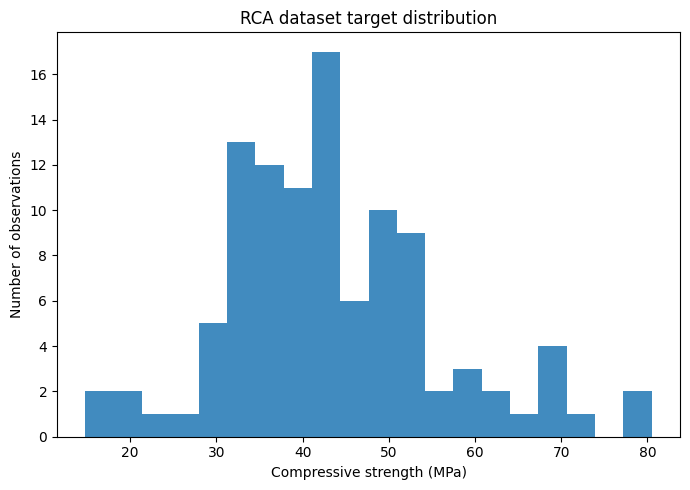

Saved: /content/figures/target_distribution_rca.png


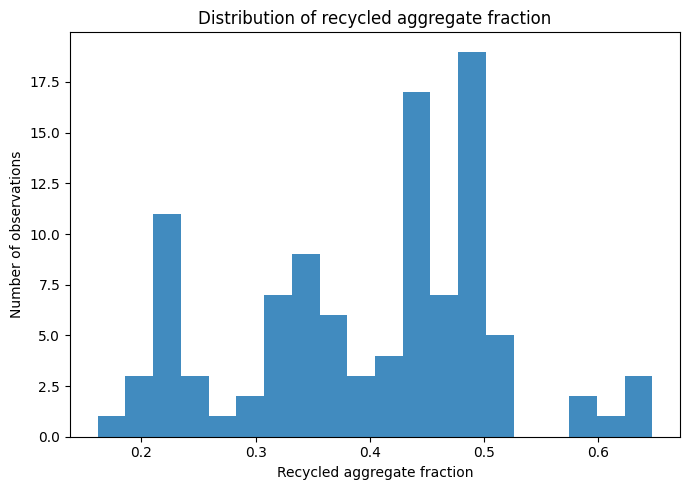

Saved: /content/figures/recycled_aggregate_fraction_distribution_rca.png


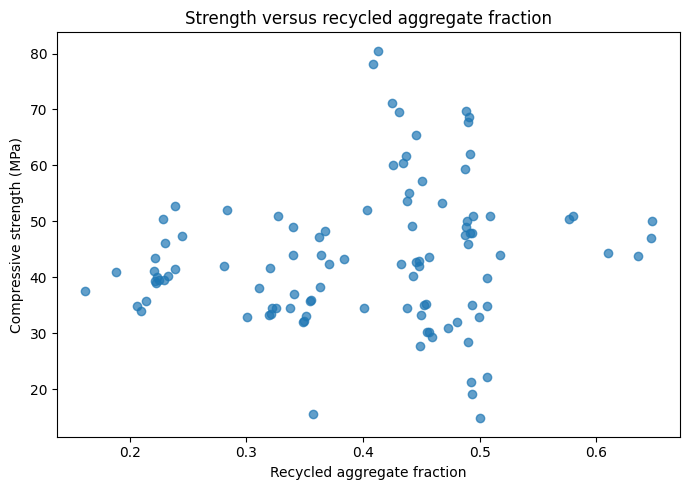

Saved: /content/figures/strength_vs_recycled_fraction_rca.png


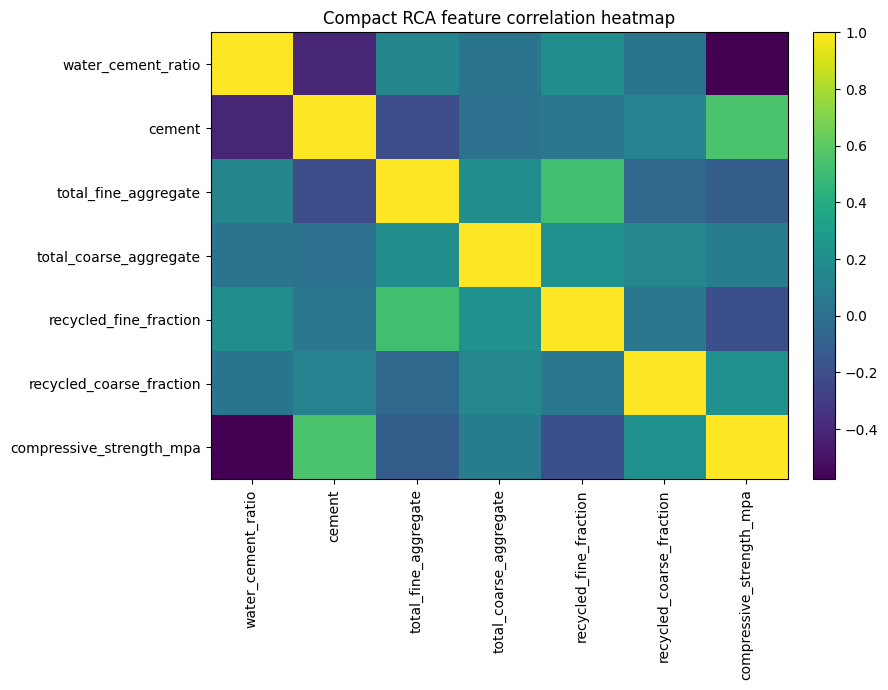

Saved: /content/figures/correlation_heatmap_rca.png


In [9]:
# Creates statistics summary for each feature before creating publication-ready figures
# Acts as a way to check for reasonable ranges and distributions in the data
summary_columns = list(
    dict.fromkeys(
        [
            *base_verified_features,
            "total_recycled_aggregate",
            "recycled_aggregate_fraction",
            TARGET_COL,
        ]
    )
)

summary_stats = (
    model_df[summary_columns]
    .describe()
    .T
)

summary_path = (
    OUT_DIR / "rca_summary_statistics_rca.csv"
)

summary_stats.to_csv(summary_path)

print("Saved:", summary_path)
display(summary_stats)
# ============================================================
# Target distribution graphs
# ============================================================
# Histogram graph shows how the variable varies and shows the mean/median
# Can be used to improve clustering around a specific value
# Applies to both the compressive strength and recycled aggregate fraction histograms

# Concrete compressive strength distribution
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(
    model_df[TARGET_COL],
    bins=20,
    alpha=0.85,
)

ax.set_xlabel(
    "Compressive strength (MPa)"
)
ax.set_ylabel(
    "Number of observations"
)
ax.set_title(
    "RCA dataset target distribution"
)

fig.tight_layout()

fig_path = (
    FIG_DIR / "target_distribution_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

# Recycled aggregate (RA) fraction distribution
# Note that this variable refers to the percentage of RA that makes up the total aggregates
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(
    model_df["recycled_aggregate_fraction"],
    bins=20,
    alpha=0.85
)

ax.set_xlabel(
    "Recycled aggregate fraction"
)

ax.set_ylabel(
    "Number of observations"
)

ax.set_title(
    "Distribution of recycled aggregate fraction"
)

fig.tight_layout()

fig_path = (
    FIG_DIR / f"recycled_aggregate_fraction_distribution_{OUTPUT_PREFIX}.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fig_path)
# ============================================================
# Scatterplot graph
# ============================================================
# Compares concrete compressive strength to recycled aggregate fraction
# Analyzes how compressive strength varies as RA is integrated

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    model_df[
        "recycled_aggregate_fraction"
    ],
    model_df[TARGET_COL],
    alpha=0.70,
)

ax.set_xlabel(
    "Recycled aggregate fraction"
)
ax.set_ylabel(
    "Compressive strength (MPa)"
)
ax.set_title(
    "Strength versus recycled aggregate fraction"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / "strength_vs_recycled_fraction_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

corr_columns = list(
    dict.fromkeys(
        [
            *FEATURE_SETS["compact_physical"],
            TARGET_COL,
        ]
    )
)

corr = model_df[
    corr_columns
].corr(numeric_only=True)
# ============================================================
# Correlation heatmap
# ============================================================
# Correlation heatmap represents the relationship between materials
# Yellow is positive correlation (increases together)
# Purple is negative correlation (decreases together)
# Model-independent

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    corr.values,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(corr.columns))
)
ax.set_yticks(
    np.arange(len(corr.index))
)

ax.set_xticklabels(
    corr.columns,
    rotation=90,
)

ax.set_yticklabels(
    corr.index,
)

ax.set_title(
    "Compact RCA feature correlation heatmap"
)

fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

fig.tight_layout()

fig_path = (
    FIG_DIR / "correlation_heatmap_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)


**Target Distribution Histogram:** The target distribution graph shows a heavy amount of clustering between 30-50 MPa. This communicates that model predictions within these compressive strength ranges should be interpreted more carefully. Adding a higher number of mixtures in the dataset for low- and high-strength mixtures may reduce uncertainty, but error analysis should still be performed to verify model accuracy.


**Recycled Aggregate Fraction Distribution Histogram:** Mixtures with 40-50% recycled aggregate replacement seem to be the most prevalent, alongside a noticeable spike near 20% recycled aggregate replacement. This communicates that the trained models may have less error within these recycled aggregate ranges due to the larger sample size relative to other ranges. It also demonstrates that mixtures with a high recycled aggregate content should be interpreted with caution, as the models have minimal training data.


**Strength vs. Recycled Aggregate Fraction Scatterplot:** The scatterplot shows a similar result to the recycled aggregate and target distribution histograms, with a high frequency of mixtures between 30-50 MPa and 40-50% recycled aggregate replacement. Sparsely represented ranges, such as between 60-80 MPa and 0-40% recycled aggregate replacement, indicate areas that require more cautious interpretation.


**Correlation Heatmap:** The purpose of this graph is to analyze the exploratory relationships between variables in the present dataset. Notable relationships include the positive correlation between cement and compressive strength, which is present in the UCI dataset in previous notebooks. A negative correlation can be seen between compressive strength and water-cement ratio, indicating its importance in predicting concrete compressive strength. However, it only provides exploratory context for the present data and should not be interpreted as causal evidence or as a replacement for model-based feature importance.

## 8. Define mixture groups and the primary grouped hold-out split

Rows with the same original mixture inputs are assigned to the same group. This prevents the same mixture design from appearing in both training and evaluation subsets.

In [10]:
GROUP_COLUMNS = [
    "water_cement_ratio",
    "water",
    "aggregate_cement_ratio",
    "cement",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_coarse_aggregate",
    "recycled_fine_aggregate",
]

# Assigns a unique ID to every mixture to call and differentiate between dataset rows
mix_groups = pd.util.hash_pandas_object(
    model_df[GROUP_COLUMNS].round(8),
    index=False,
).astype(str)

# Prints the number of mixtures and any repeated rows
print(
    "Rows:",
    len(model_df),
)
print(
    "Unique mixture groups:",
    mix_groups.nunique(),
)
print(
    "Repeated-group rows:",
    int(mix_groups.duplicated(keep=False).sum()),
)

all_indices = np.arange(len(model_df))

# Creates a group shuffle split object
# Prevents test data memorization by only allowing a mixture to appear in either
# the test set or the train set
# 20% of the rows go into the test set
primary_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

# Runs the group shuffle split
train_idx, test_idx = next(
    primary_splitter.split(
        all_indices,
        model_df[TARGET_COL],
        groups=mix_groups,
    )
)

# Saves the split
groups_train = mix_groups.iloc[train_idx]
groups_test = mix_groups.iloc[test_idx]

# Checks that a mixture appears in only the test or train set
if set(groups_train).intersection(set(groups_test)):
    raise RuntimeError(
        "Group leakage detected in the primary split."
    )

# Extracts the target varaible for the training/testing rows
y_train = (
    model_df[TARGET_COL]
    .iloc[train_idx]
    .copy()
)

y_test = (
    model_df[TARGET_COL]
    .iloc[test_idx]
    .copy()
)

# Prints results for confirmation
print("Training rows:", len(train_idx))
print("Held-out test rows:", len(test_idx))
print(
    "Training mixture groups:",
    groups_train.nunique(),
)
print(
    "Test mixture groups:",
    groups_test.nunique(),
)

Rows: 104
Unique mixture groups: 103
Repeated-group rows: 2
Training rows: 83
Held-out test rows: 21
Training mixture groups: 82
Test mixture groups: 21


In [11]:
# Creates grouped cross-validation object for machine learning model evaluation
# Keeps samples from the same group together in either a training or test set
# Unlike 5-fold cross-validation, which can split groups across both train
# and test sets
def make_group_cv(groups, maximum_splits=5):
    unique_group_count = pd.Series(
        groups
    ).nunique()

    # Prevents the creation of more folds than groups
    n_splits = min(
        maximum_splits,
        int(unique_group_count),
    )

    # Error message if the number of unique groups are less than 2
    if n_splits < 2:
        raise ValueError(
            "At least two unique groups are required."
        )

    return GroupKFold(
        n_splits=n_splits,
    )


# Sets up evaluation metrics testing the model's predictive accuracy
# R^2 measures the variation between the actual vs predicted value
# MAE is the mean absolute error
    # All errors are treated the same
# RMSE is the root mean square error
    # More sensitive to outliers than MAE and penalizes larger deviations in magnitude
def evaluate_predictions(
    y_true,
    y_pred,
):
    return {
        "r2": r2_score(
            y_true,
            y_pred,
        ),
        "mae_mpa": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "rmse_mpa": (
            mean_squared_error(
                y_true,
                y_pred,
            )
            ** 0.5
        ),
    }


group_cv = make_group_cv(
    groups_train,
    maximum_splits=5,
)

# Defines all models into a single variable for referencing
UNTUNED_MODELS = {
    "LinearRegression": Pipeline(
        [
            (
                "scaler",
                StandardScaler(),
            ),
            (
                "model",
                LinearRegression(),
            ),
        ]
    ),

    "RandomForest": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),

    "GradientBoosting": (
        GradientBoostingRegressor(
            random_state=RANDOM_STATE,
        )
    ),
}

**Result Interpretation:** As seen in the printed results, there are 104 cleaned rows and 103 unique mixture groups. This indicates that most of the mixtures are unique within the cleaned dataset. However, despite using a GroupKFold, completely preventing leakage between similar mixtures is not achievable. Study, batch, or experimental-series identifiers are not available for the RCA dataset used and should be considered a limitation for the present study.

## 9. Feature-set ablation and untuned baseline comparison

Every feature set is evaluated only on the training portion using group-aware cross-validation. This identifies whether engineered and redundant features genuinely improve generalization.

In [12]:
# This code block performs the bulk of the model training and evaluation
# Runs feature ablation, testing the importance of specific features
# Compares predefined feature sets to determine its effect on model accuracy
ablation_rows = []

# Loops through feature sets then selects only the features used in training
for feature_set_name, feature_columns in FEATURE_SETS.items():
    X_feature_set = model_df[
        feature_columns
    ]

    # Ensures only training portion of data is used
    X_train_feature_set = (
        X_feature_set
        .iloc[train_idx]
        .copy()
    )

    # Selects defined models and runs cross-validation calculations
    for model_name, estimator in UNTUNED_MODELS.items():
        cv_result = cross_validate(
            estimator,
            X_train_feature_set,
            y_train,
            groups=groups_train,
            cv=group_cv,
            scoring={
                "r2": "r2",
                "mae": (
                    "neg_mean_absolute_error"
                ),
            },
            n_jobs=1,
        )

        # Saves the averaged results
        ablation_rows.append(
            {
                "feature_set": feature_set_name,
                "model": model_name,
                "feature_count": len(
                    feature_columns
                ),
                "cv_r2_mean": (
                    cv_result[
                        "test_r2"
                    ].mean()
                ),
                "cv_r2_std": (
                    cv_result[
                        "test_r2"
                    ].std()
                ),
                "cv_mae_mpa_mean": (
                    -cv_result[
                        "test_mae"
                    ].mean()
                ),
                "cv_mae_mpa_std": (
                    cv_result[
                        "test_mae"
                    ].std()
                ),
            }
        )

# Converts everything into a DataFrame and sorts by performance
# Saves the results into outputs for publication, then prints
ablation_df = (
    pd.DataFrame(ablation_rows)
    .sort_values(
        [
            "cv_r2_mean",
            "cv_mae_mpa_mean",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

ablation_path = (
    OUT_DIR
    / "rca_feature_ablation_group_cv_rca.csv"
)

ablation_df.to_csv(
    ablation_path,
    index=False,
)

print("Saved:", ablation_path)
display(ablation_df)

# Selects the best performing features in increasing predictive accuracy
# Utilized in the remaining code as the most impactful in determining model accuracy
selected_feature_set_name = (
    ablation_df.iloc[0][
        "feature_set"
    ]
)

selected_features = FEATURE_SETS[
    selected_feature_set_name
]

print(
    "Selected feature set from training group CV:",
    selected_feature_set_name,
)
print(
    "Selected features:",
    selected_features,
)

Saved: /content/outputs/rca_feature_ablation_group_cv_rca.csv


,feature_set,model,feature_count,cv_r2_mean,cv_r2_std,cv_mae_mpa_mean,cv_mae_mpa_std
0,verified_original,RandomForest,8,0.782686,0.115858,3.783918,0.689412
1,compact_physical,GradientBoosting,6,0.751731,0.106570,4.260056,0.825799
2,verified_original,GradientBoosting,8,0.748557,0.112845,4.158758,0.751599
3,full_engineered,RandomForest,17,0.736133,0.114562,4.281298,0.773010
4,compact_physical,RandomForest,6,0.728352,0.086090,4.506236,0.658466
5,full_engineered,GradientBoosting,17,0.714312,0.124618,4.490993,0.797144
6,full_engineered,LinearRegression,17,0.526653,0.281076,5.675059,1.542144
7,verified_original,LinearRegression,8,0.451902,0.151833,6.583744,0.928287
8,compact_physical,LinearRegression,6,0.310813,0.204301,7.471315,0.878396


Selected feature set from training group CV: verified_original
Selected features: ['water_cement_ratio', 'water', 'aggregate_cement_ratio', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate']


**Result Interpretation:** The verified original feature set produced the strongest cross-validation performance with the highest R^2 value. Adding engineered and redundant variables does not appear to improve the generalization within the present dataset.

## 10. Group-aware hyperparameter tuning and model selection

Random Forest and Gradient Boosting are tuned using `GroupKFold`. Linear Regression remains an untuned reference. The held-out test set is not used for model selection.

In [13]:
# Creates a new DataFrame with the best features for hyperparameter tuning
X_selected = model_df[
    selected_features
].copy()

# Creates test and training sets based on new DataFrame for tuning
X_train = (
    X_selected
    .iloc[train_idx]
    .copy()
)

X_test = (
    X_selected
    .iloc[test_idx]
    .copy()
)

# Setting up a random forest hyperparameter grid for tuning
RF_GRID = {
    # Number of trees
    "n_estimators": [200, 400],
    # Maximum depth each individual decision tree (growth limit)
    "max_depth": [None, 8, 14],
    # Minimum number of samples in final prediction of each tree
    "min_samples_leaf": [1, 2, 4],
}

# Setting up a gradient boosting hyperparameter grid for tuning
GBR_GRID = {
    # Number of boosting stages or sequential decision trees
    "n_estimators": [150, 300],
    # Shrinkage factor, contribution of each individual tree
    "learning_rate": [0.03, 0.07, 0.10],
    # Maximum depth of each individual regression tree
    # Controls complexity of each learner
    "max_depth": [2, 3],
}

# Print out best parameters and best cross-validation score for each model
# Includes basic linear regression
rf_search = GridSearchCV(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    RF_GRID,
    cv=group_cv,
    scoring="r2",
    n_jobs=-1,
)

gbr_search = GridSearchCV(
    GradientBoostingRegressor(
        random_state=RANDOM_STATE,
    ),
    GBR_GRID,
    cv=group_cv,
    scoring="r2",
    n_jobs=-1,
)

rf_search.fit(
    X_train,
    y_train,
    groups=groups_train,
)

gbr_search.fit(
    X_train,
    y_train,
    groups=groups_train,
)

# Defines variables for untuned models
linear_estimator = UNTUNED_MODELS["LinearRegression"]
forest_estimator = UNTUNED_MODELS["RandomForest"]
gradient_estimator = UNTUNED_MODELS["GradientBoosting"]

# Adds linear regression and untuned models for comparison
linear_cv = cross_validate(
    linear_estimator,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
    },
    n_jobs=1,
)

rf_cv = cross_validate(
    forest_estimator,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring="r2",
    n_jobs=1,
)

gbr_cv = cross_validate(
    gradient_estimator,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring="r2",
    n_jobs=1,
)

candidate_cv_scores = {
    "LinearRegression": (
        linear_cv["test_r2"].mean()
    ),
    "RandomForest_untuned": (
        rf_cv["test_score"].mean()
    ),
    "GradientBoosting_untuned": (
        gbr_cv["test_score"].mean()
    ),
    "RandomForest_tuned": (
        rf_search.best_score_
    ),
    "GradientBoosting_tuned": (
        gbr_search.best_score_
    ),
}

candidate_estimators = {
    "LinearRegression": (
        linear_estimator
    ),
    "RandomForest_untuned": (
        forest_estimator
    ),
    "GradientBoosting_untuned": (
        gradient_estimator
    ),
    "RandomForest_tuned": (
        rf_search.best_estimator_
    ),
    "GradientBoosting_tuned": (
        gbr_search.best_estimator_
    ),
}

# Calculates and displays the results of the hyperparameter tuning
# Compares cross-validation r2 values and gives the best parameters for each model
tuning_summary = pd.DataFrame(
    [
        {
            "model": "LinearRegression",
            "best_group_cv_r2": (
                candidate_cv_scores[
                    "LinearRegression"
                ]
            ),
            "best_params": (
                json.dumps({})
            ),
        },
        {
            "model": "RandomForest_untuned",
            "best_group_cv_r2": (
                candidate_cv_scores[
                    "RandomForest_untuned"
                ]
            ),
            "best_params": json.dumps({}),
        },
        {
            "model": "GradientBoosting_untuned",
            "best_group_cv_r2": (
                candidate_cv_scores[
                    "GradientBoosting_untuned"
                ]
            ),
            "best_params": json.dumps({}),
        },
        {
            "model": "RandomForest_tuned",
            "best_group_cv_r2": (
                rf_search.best_score_
            ),
            "best_params": json.dumps(
                rf_search.best_params_
            ),
        },
        {
            "model": "GradientBoosting_tuned",
            "best_group_cv_r2": (
                gbr_search.best_score_
            ),
            "best_params": json.dumps(
                gbr_search.best_params_
            ),
        },
    ]

# Searches for the best model after group cross-validation is run
).sort_values(
    "best_group_cv_r2",
    ascending=False,
)

selected_name = max(
    candidate_cv_scores,
    key=candidate_cv_scores.get,
)

# Creates a untrained copy of the best model for a second training set
selected_model = clone(
    candidate_estimators[
        selected_name
    ]
)

# Retrains with all the training data
selected_model.fit(
    X_train,
    y_train,
)

# Compares new model with the test set for predictive accuracy
# Then calculates the final metrics
selected_pred = selected_model.predict(
    X_test
)

final_metrics = evaluate_predictions(
    y_test,
    selected_pred,
)

# Saves tuning summary to outputs for publication
tuning_summary_path = (
    OUT_DIR
    / "rca_group_tuning_summary_rca.csv"
)

tuning_summary.to_csv(
    tuning_summary_path,
    index=False,
)

# Creates a second table displaying the best model and relevant information
# Calculates in pandas Dataframe and saves the table to outputs
final_results = pd.DataFrame(
    [
        {
            "selected_feature_set": (
                selected_feature_set_name
            ),
            "selected_model": (
                selected_name
            ),
            "selection_group_cv_r2": (
                candidate_cv_scores[
                    selected_name
                ]
            ),
            "train_rows": len(X_train),
            "test_rows": len(X_test),
            **final_metrics,
        }
    ]
)

# Saves then displays a table describing the best model
final_results_path = (
    OUT_DIR
    / "rca_final_model_test_results_rca.csv"
)

final_results.to_csv(
    final_results_path,
    index=False,
)

print("Saved:", tuning_summary_path)
print("Saved:", final_results_path)

display(tuning_summary)
display(final_results)

Saved: /content/outputs/rca_group_tuning_summary_rca.csv
Saved: /content/outputs/rca_final_model_test_results_rca.csv


,model,best_group_cv_r2,best_params
3,RandomForest_tuned,0.785200,"{""max_depth"": 14, ""min_samples_leaf"": 1, ""n_es..."
1,RandomForest_untuned,0.782686,{}
4,GradientBoosting_tuned,0.765831,"{""learning_rate"": 0.07, ""max_depth"": 3, ""n_est..."
2,GradientBoosting_untuned,0.748557,{}
0,LinearRegression,0.451902,{}


,selected_feature_set,selected_model,selection_group_cv_r2,train_rows,test_rows,r2,mae_mpa,rmse_mpa
0,verified_original,RandomForest_tuned,0.7852,83,21,0.674977,4.462595,6.945269


**Result Interpretation:** The best model is selected from both tuned and untuned models in this code. The selection process is put into more detail under the markdown in Section 11. The current regression models being tested are shown below:

- Linear Regression
- Untuned Random Forest
- Untuned Gradient Boosting
- Tuned Random Forest
- Tuned Gradient Boosting

Note that whether a model is tuned or not does not determine if it is selected. If an untuned model has a higher grouped cross-validation R^2 value, that model should be selected over the tuned models. A more detailed summary exists after the error analysis in Section 11 of the code.

## 11. Tuning comparison and final held-out diagnostics

Hyperparameter tuning is discussed using the change in group cross-validation performance. A lower score on the single held-out set does not mean tuning was incorrectly performed, but it does show that the tuning benefit is not uniform across splits.

Saved: /content/outputs/rca_tuning_effect_summary_rca.csv


,selected_model,untuned_family,untuned_group_cv_r2,tuned_group_cv_r2,group_cv_r2_change
0,RandomForest_tuned,RandomForest,0.782686,0.7852,0.002514


Saved: /content/outputs/rca_test_predictions_RandomForest_tuned_rca.csv


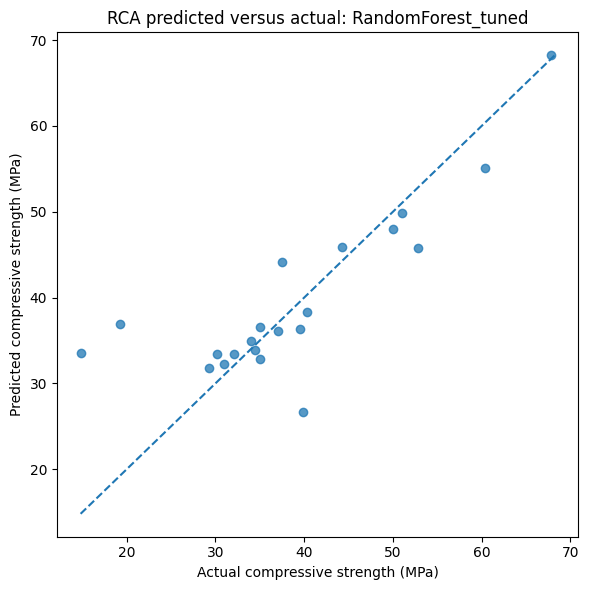

Saved: /content/figures/pred_vs_actual_RandomForest_tuned_rca.png


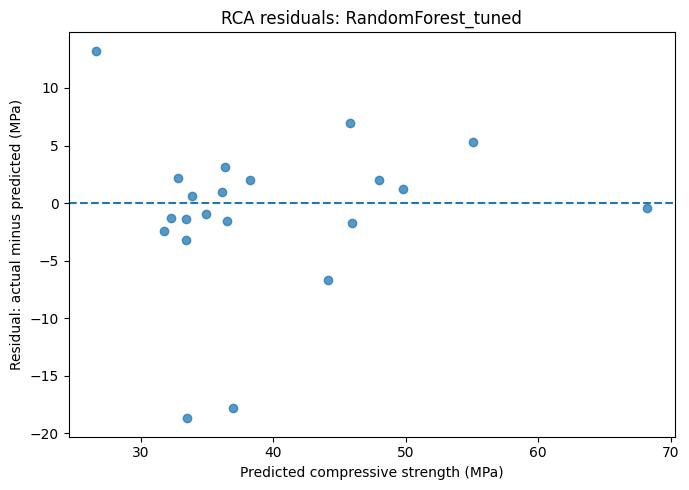

Saved: /content/figures/residual_plot_RandomForest_tuned_rca.png


In [14]:
# Defines the untuned version of the best performing model
# Used to determine if tuning was beneficial in improving model accuracy
untuned_same_family_name = (
    selected_name.replace(
        "_tuned",
        "",
    )
)

# Grabs the results of the untuned model
untuned_selected_row = (
    ablation_df[
        (
            ablation_df["feature_set"]
            == selected_feature_set_name
        )
        & (
            ablation_df["model"]
            == untuned_same_family_name
        )
    ]
)

if len(untuned_selected_row) == 1:
    untuned_family_cv_r2 = float(
        untuned_selected_row.iloc[0][
            "cv_r2_mean"
        ]
    )
else:
    untuned_family_cv_r2 = np.nan

# Compute the R^2 improvement from tuning the model
tuning_delta_cv_r2 = (
    candidate_cv_scores[
        selected_name
    ]
    - untuned_family_cv_r2
)

# Create a summary table of the results for viewing
# Acts as supporting evidence for how tuning affected model accuracy
tuning_effect_df = pd.DataFrame(
    [
        {
            "selected_model": selected_name,
            "untuned_family": (
                untuned_same_family_name
            ),
            "untuned_group_cv_r2": (
                untuned_family_cv_r2
            ),
            "tuned_group_cv_r2": (
                candidate_cv_scores[
                    selected_name
                ]
            ),
            "group_cv_r2_change": (
                tuning_delta_cv_r2
            ),
        }
    ]
)

tuning_effect_path = (
    OUT_DIR
    / "rca_tuning_effect_summary_rca.csv"
)

tuning_effect_df.to_csv(
    tuning_effect_path,
    index=False,
)

print("Saved:", tuning_effect_path)
display(tuning_effect_df)

# Creates a table comparing actual vs. predicted concrete compressive strength values
# Calculates residuals for concrete compressive strength
prediction_df = pd.DataFrame(
    {
        "source_row_number": (
            model_df[
                "source_row_number"
            ].iloc[test_idx].to_numpy()
        ),
        "actual_strength_mpa": (
            y_test.to_numpy()
        ),
        "predicted_strength_mpa": (
            selected_pred
        ),
    }
)

prediction_df["residual_mpa"] = (
    prediction_df[
        "actual_strength_mpa"
    ]
    - prediction_df[
        "predicted_strength_mpa"
    ]
)

prediction_df["absolute_error_mpa"] = (
    prediction_df[
        "residual_mpa"
    ].abs()
)

prediction_path = (
    OUT_DIR
    / (
        f"rca_test_predictions_"
        f"{selected_name}_rca.csv"
    )
)

prediction_df.to_csv(
    prediction_path,
    index=False,
)

print("Saved:", prediction_path)
# ============================================================
# Predicted vs. Actual Strength Scatterplot
# ============================================================
# Test how close the model comes to a 1:1 correlation to determine model accuracy
# Saved to figures for publication

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    prediction_df[
        "actual_strength_mpa"
    ],
    prediction_df[
        "predicted_strength_mpa"
    ],
    alpha=0.75,
)

# Places 45-degree line
# Provides a visual aid to determine model accuracy
limits = [
    min(
        prediction_df[
            "actual_strength_mpa"
        ].min(),
        prediction_df[
            "predicted_strength_mpa"
        ].min(),
    ),
    max(
        prediction_df[
            "actual_strength_mpa"
        ].max(),
        prediction_df[
            "predicted_strength_mpa"
        ].max(),
    ),
]

ax.plot(
    limits,
    limits,
    linestyle="--",
)

ax.set_xlabel(
    "Actual compressive strength (MPa)"
)
ax.set_ylabel(
    "Predicted compressive strength (MPa)"
)
ax.set_title(
    f"RCA predicted versus actual: {selected_name}"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / (
        f"pred_vs_actual_"
        f"{selected_name}_rca.png"
    )
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

# ============================================================
# RCA Residual Scatterplot
# ============================================================
# Negative = Overpredicted
# Positive = Underpredicted
# Provides another way to graph model accuracy
# Saved to figures for publication
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    prediction_df[
        "predicted_strength_mpa"
    ],
    prediction_df[
        "residual_mpa"
    ],
    alpha=0.75,
)

# Reference line
ax.axhline(
    0,
    linestyle="--",
)

ax.set_xlabel(
    "Predicted compressive strength (MPa)"
)
ax.set_ylabel(
    "Residual: actual minus predicted (MPa)"
)
ax.set_title(
    f"RCA residuals: {selected_name}"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / (
        f"residual_plot_"
        f"{selected_name}_rca.png"
    )
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

Model selection was performed in Section 10 of the code using grouped cross-validation on the training data. The R^2 value from this grouped cross-validation is used to select the best performing regression model (referred to as selection_group_cv_r2). The selected model is then retrained using the training split and run on the held-out test set to then be used for error analysis.

Section 11 compares the tuned and untuned versions of this selected model and records the results. If the untuned model performs better than the selected tuned model, it is used instead. An evaluation of the current selected model is listed below:

- Dataset: verified_original
- Model Name: RandomForest_tuned
- Primary hold-out R² ≈ 0.675
- Primary hold-out MAE ≈ 4.463 MPa
- Primary hold-out RMSE ≈ 6.945 MPa

The R^2 is not a universal model performance value, but rather the predictive performance on a given held-out split from the RCA dataset. Also note that the tuning effect for the R^2 was a 0.003 increase, possibly indicating that tuning had a limited effect on improving the model's predictive performance. A summary of the error analysis conducted on the regression model is listed below:

**Predicted vs. Actual Scatterplot:** Most predictions follow the one-to-one line, but larger errors at lower and higher strength mixtures. This is consistent with the target and recycled aggregate distribution histograms, as less data exists at those ranges to train the models.

**Residual Scatterplot:** The figure shows a large range for the residual values. Significant overpredictions and underpredictions exist at low and high predicted compressive strengths. More detailed conclusions cannot be reached due to the small test set.

Saved: /content/outputs/permutation_importance_RandomForest_tuned_rca.csv


,feature,importance_mean,importance_std
0,water_cement_ratio,0.930938,0.365136
1,water,0.238164,0.093339
5,natural_coarse_aggregate,0.038033,0.016061
3,cement,0.034530,0.020273
6,recycled_coarse_aggregate,0.001889,0.015504
2,aggregate_cement_ratio,-0.000610,0.000354
4,natural_fine_aggregate,-0.005180,0.030345
7,recycled_fine_aggregate,-0.050288,0.022383


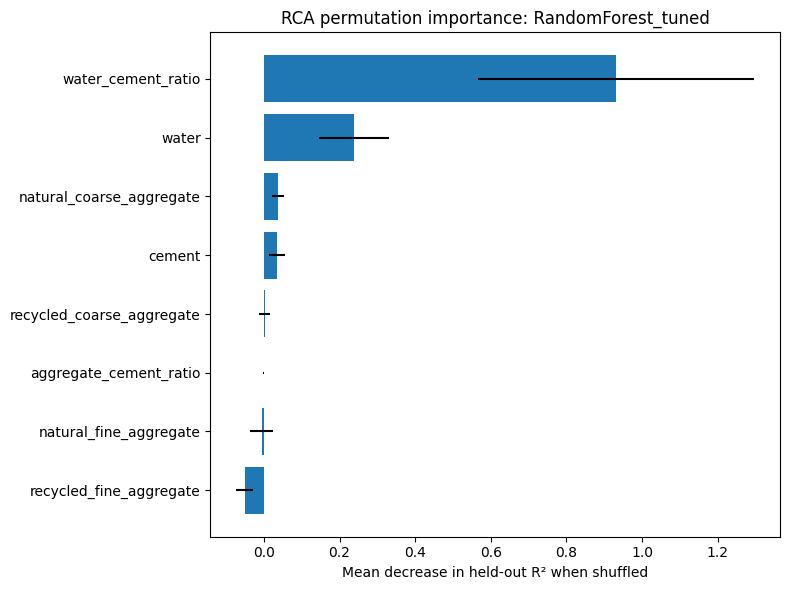

Saved: /content/figures/feature_importance_RandomForest_tuned_rca.png


In [15]:
# Measures importance of each variable using "r2" as a scoring metric
# Only refers to importance in predicting concrete compressive strength
# See more in graph explanations
permutation_result = permutation_importance(
    selected_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring="r2",
)

# Sorts variables and provides mean + STD for each
importance_df = pd.DataFrame(
    {
        "feature": selected_features,
        "importance_mean": (
            permutation_result
            .importances_mean
        ),
        "importance_std": (
            permutation_result
            .importances_std
        ),
    }
).sort_values(
    "importance_mean",
    ascending=False,
)

# Saves table for publication
importance_path = (
    OUT_DIR
    / (
        f"permutation_importance_"
        f"{selected_name}_rca.csv"
    )
)

importance_df.to_csv(
    importance_path,
    index=False,
)

print("Saved:", importance_path)
display(importance_df)

# ============================================================
# Permutation Importance Bar Graph
# ============================================================
# Considers the importance of a feature in model predictions
# Model and dataset-specific; does not apply outside the fitted model

fig, ax = plt.subplots(figsize=(8, 6))

top_importance = (
    importance_df
    .head(
        min(
            12,
            len(importance_df),
        )
    )
    .iloc[::-1]
)

ax.barh(
    top_importance["feature"],
    top_importance["importance_mean"],
    xerr=top_importance[
        "importance_std"
    ],
)

ax.set_xlabel(
    "Mean decrease in held-out R² when shuffled"
)
ax.set_title(
    f"RCA permutation importance: {selected_name}"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / (
        f"feature_importance_"
        f"{selected_name}_rca.png"
    )
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

**Permutation Importance Bar Graph:** The water-cement ratio and water content of the mixtures are the strongest predictive variables within this fitted model. However, it is also important to note the permutation importance is calculated on a small held-out test set of 21 observations. This  means that this importance is exploratory/model-specific, and should not be considered direct physical or causal effects. Other features seem to be significantly less important in model predictions based on the permutation importance, the most notable of which being fine aggregates and aggregate-cement ratio.

## 12. Repeated nested grouped feature-set and model selection

The primary hold-out result is only one split. This section repeats the full group-aware model-selection process across multiple outer grouped splits. Each outer split performs its own inner group-aware tuning before evaluating an untouched outer test subset.

These results provide a more realistic estimate of model-development variability than resampling one fixed set of predictions. However, due to the small number of mixtures, the grouped split only changes a small number of repeated mixtures. Exact-value grouped also does not necessarily prevent similar formulations or mixtures from appearing across different folds. Therefore, this is currently considered a limitation of the present study.

Split 1 selected feature set: verified_original
Selected features: ['water_cement_ratio', 'water', 'aggregate_cement_ratio', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate']
Split 2 selected feature set: verified_original
Selected features: ['water_cement_ratio', 'water', 'aggregate_cement_ratio', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate']
Split 3 selected feature set: full_engineered
Selected features: ['water_cement_ratio', 'water', 'aggregate_cement_ratio', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate', 'total_natural_aggregate', 'total_recycled_aggregate', 'total_fine_aggregate', 'total_coarse_aggregate', 'total_aggregate', 'recycled_aggregate_fraction', 'recycled_coarse_fraction', 'recycled_fine_fraction', 'water_to_cement_from_quantities']
Split 4 selected featur

,split_number,selected_feature_set,selected_model,inner_group_cv_r2,outer_train_rows,outer_test_rows,r2,mae_mpa,rmse_mpa
0,1,verified_original,GradientBoosting_tuned,0.746141,83,21,0.704863,4.607880,6.618254
1,2,verified_original,RandomForest_untuned,0.727459,83,21,0.833184,4.187758,6.091715
2,3,full_engineered,GradientBoosting_tuned,0.677566,83,21,0.821848,5.047038,5.978766
3,4,compact_physical,GradientBoosting_tuned,0.800216,83,21,0.766009,4.879562,6.364308
4,5,full_engineered,GradientBoosting_tuned,0.797421,83,21,0.693340,3.868865,4.880870
5,6,full_engineered,GradientBoosting_untuned,0.739783,83,21,0.833559,3.893210,4.912545
6,7,compact_physical,RandomForest_untuned,0.725577,82,22,0.737846,4.358546,5.512154
7,8,full_engineered,GradientBoosting_tuned,0.755570,83,21,0.864413,3.535750,4.538479
8,9,compact_physical,RandomForest_untuned,0.730378,83,21,0.827065,5.254175,6.342192
9,10,full_engineered,GradientBoosting_tuned,0.692883,83,21,0.895069,2.693241,4.269397


,metric,median,iqr_25,iqr_75,range_2_5,range_97_5,minimum,maximum
0,r2,0.806324,0.739764,0.855210,0.644960,0.904209,0.623926,0.928304
1,mae_mpa,4.093361,3.871822,4.757950,2.592076,6.642199,2.325370,7.258885
2,rmse_mpa,5.565169,4.874899,6.294219,3.713119,8.781044,3.124102,8.932268


Model-selection counts:


,count
selected_model,
GradientBoosting_tuned,17
GradientBoosting_untuned,6
RandomForest_untuned,4
RandomForest_tuned,3


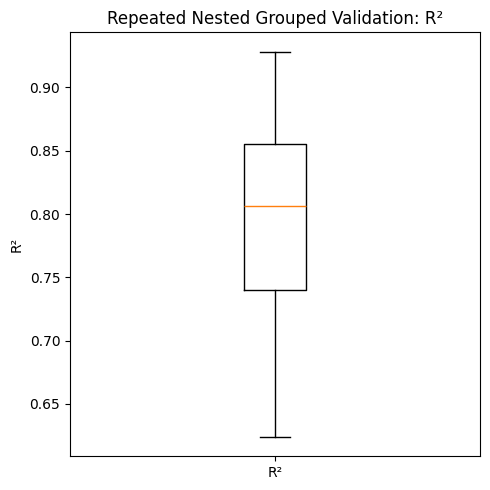

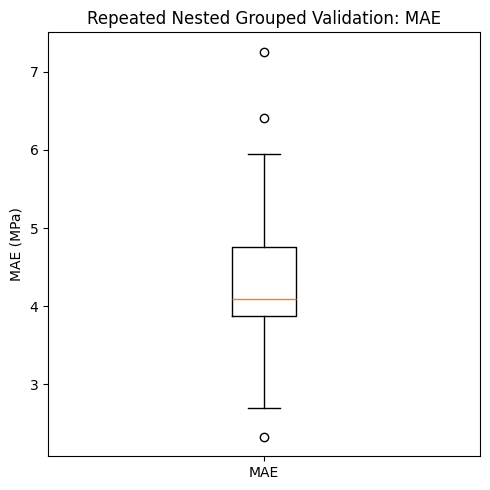

Saved: /content/figures/repeated_group_validation_r2_rca.png
Saved: /content/figures/repeated_group_validation_mae_rca.png


In [16]:
# Defines the input variables before setting up grouped splits
def tune_and_select_with_groups(
    X_outer_train,
    y_outer_train,
    groups_outer_train,
):
    # Sets a grouped 4-fold max cross-validation for tuning
    inner_cv = make_group_cv(
        groups_outer_train,
        maximum_splits=4,
    )

    # Runs random forest hyperparameter tuning and evaluated with grouped cross-validation
    rf_inner = GridSearchCV(
        RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        RF_GRID,
        cv=inner_cv,
        scoring="r2",
        n_jobs=-1,
    )

    # Runs gradient boosting hyperparameter tuning and evaluated with grouped cross-validation
    gb_inner = GridSearchCV(
        GradientBoostingRegressor(
            random_state=RANDOM_STATE,
        ),
        GBR_GRID,
        cv=inner_cv,
        scoring="r2",
        n_jobs=-1,
    )

    # Runs a grid search to train both the random forest and gradient boosting models
    # Uses the training set data and hyperparameter tuning for optimal configurations
    rf_inner.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    gb_inner.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    # Evaluates the linear regression model
    linear_inner = cross_validate(
        clone(linear_estimator),
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
        cv=inner_cv,
        scoring="r2",
        n_jobs=1,
    )

    # Evaluates the untuned random forest model
    rf_untuned_inner = cross_validate(
    clone(forest_estimator),
    X_outer_train,
    y_outer_train,
    groups=groups_outer_train,
    cv=inner_cv,
    scoring="r2",
    n_jobs=1,
    )

    # Evaluates the untuned gradient boosting model
    gb_untuned_inner = cross_validate(
    clone(gradient_estimator),
    X_outer_train,
    y_outer_train,
    groups=groups_outer_train,
    cv=inner_cv,
    scoring="r2",
    n_jobs=1,
    )

    # Scores each model using R^2 values
    # Used later for determining the best model
    scores = {
        "LinearRegression": (
            linear_inner[
                "test_score"
            ].mean()
        ),
        "RandomForest_untuned": (
            rf_untuned_inner[
                "test_score"
            ].mean()
        ),
        "GradientBoosting_untuned": (
            gb_untuned_inner[
                "test_score"
            ].mean()
        ),
        "RandomForest_tuned": (
            rf_inner.best_score_
        ),
        "GradientBoosting_tuned": (
            gb_inner.best_score_
        ),
    }

    # Displays the optimal hyperparameters for each model
    # Helps with reproducibility alongside randomstate variable
    estimators = {
        "LinearRegression": (
            clone(linear_estimator)
        ),
        "RandomForest_untuned": (
            clone(forest_estimator)
        ),
        "GradientBoosting_untuned": (
            clone(gradient_estimator)
        ),
        "RandomForest_tuned": (
            clone(rf_inner.best_estimator_)
        ),
        "GradientBoosting_tuned": (
            clone(gb_inner.best_estimator_)
        ),
    }

    # Defines the best model off of the ranked R^2 scores
    best_name = max(
        scores,
        key=scores.get,
    )

    return (
        best_name,
        estimators[best_name],
        scores[best_name],
    )

# Repeated validation part of the code
# Creates multiple train/test splits for model evaluation
outer_splitter = GroupShuffleSplit(
    n_splits=N_REPEATED_GROUP_SPLITS,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

# Creates a feature set with all predefined features
all_candidate_features = list(
    dict.fromkeys(
        feature
        for feature_columns in FEATURE_SETS.values()
        for feature in feature_columns
    )
)

X_all_features = model_df[
    all_candidate_features
].copy()


# Initialize an empty list
repeated_rows = []

# Reruns a similar evaluation as the previous code for each model multiple times
    # Feature selection occurs separately inside each outer training set
    # Uses hyperparameter tuning and selecting the best model
    # The model is trained on a train-test split
    # The model performance is then saved and the process repeats
for split_number, (
    outer_train_idx,
    outer_test_idx,
) in enumerate(
    outer_splitter.split(
        X_all_features,
        model_df[TARGET_COL],
        groups=mix_groups,
    ),
    start=1,
):

    # Creates outer training and test sets for all predefined features
    X_outer_train_raw = (
        X_all_features
        .iloc[outer_train_idx]
        .copy()
    )

    X_outer_test_raw = (
        X_all_features
        .iloc[outer_test_idx]
        .copy()
    )

    y_outer_train = (
        model_df[TARGET_COL]
        .iloc[outer_train_idx]
        .copy()
    )

    y_outer_test = (
        model_df[TARGET_COL]
        .iloc[outer_test_idx]
        .copy()
    )

    groups_outer_train = (
        mix_groups.iloc[
            outer_train_idx
        ]
    )

    groups_outer_test = (
        mix_groups.iloc[
            outer_test_idx
        ]
    )

    # Checks for train/test split leakage
    if set(
        groups_outer_train
    ).intersection(
        set(groups_outer_test)
    ):
        raise RuntimeError(
            "Group leakage detected in repeated validation."
        )

    # Initializes an empty list for this outer split
    ablation_rows = []

    # Loops through predefined feature sets
    for feature_set_name, feature_columns in FEATURE_SETS.items():

        # Feature set selection with only outer training data
        X_train_feature_set = (
            X_outer_train_raw[
                feature_columns
            ]
            .copy()
        )

        # Creates grouped inner CV with only outer training groups
        inner_feature_cv = make_group_cv(
            groups_outer_train,
            maximum_splits=4,
        )

        # Evaluates each model using the feature set
        for model_name, estimator in UNTUNED_MODELS.items():

            cv_result = cross_validate(
                estimator,
                X_train_feature_set,
                y_outer_train,
                groups=groups_outer_train,
                cv=inner_feature_cv,
                scoring={
                    "r2": "r2",
                    "mae": (
                        "neg_mean_absolute_error"
                    ),
                },
                n_jobs=1,
            )

            # Saves feature set performance
            ablation_rows.append(
                {
                    "feature_set": feature_set_name,
                    "model": model_name,
                    "feature_count": len(
                        feature_columns
                    ),
                    "cv_r2_mean": (
                        cv_result[
                            "test_r2"
                        ].mean()
                    ),
                    "cv_r2_std": (
                        cv_result[
                            "test_r2"
                        ].std()
                    ),
                    "cv_mae_mpa_mean": (
                        -cv_result[
                            "test_mae"
                        ].mean()
                    ),
                    "cv_mae_mpa_std": (
                        cv_result[
                            "test_mae"
                        ].std()
                    ),
                }
            )

    # Converts results into pandas DataFrame
    ablation_df = (
        pd.DataFrame(ablation_rows)
        .sort_values(
            [
                "cv_r2_mean",
                "cv_mae_mpa_mean",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    # Selects best feature set only using outer training data for this split
    selected_feature_set_name = (
        ablation_df.iloc[0][
            "feature_set"
        ]
    )

    selected_features = FEATURE_SETS[
        selected_feature_set_name
    ]

    print(
        f"Split {split_number} selected feature set:",
        selected_feature_set_name,
    )

    print(
        "Selected features:",
        selected_features,
    )

    # Applies selected feature set to outer training/testing data
    # Note outer test data was not used to select the feature set
    X_outer_train = (
        X_outer_train_raw[
            selected_features
        ]
        .copy()
    )

    X_outer_test = (
        X_outer_test_raw[
            selected_features
        ]
        .copy()
    )

    # Runs hyperparameter tuning and model selection
    (
        split_model_name,
        split_model,
        inner_cv_r2,
    ) = tune_and_select_with_groups(
        X_outer_train,
        y_outer_train,
        groups_outer_train,
    )

    split_model.fit(
        X_outer_train,
        y_outer_train,
    )

    split_prediction = split_model.predict(
        X_outer_test
    )

    split_metrics = evaluate_predictions(
        y_outer_test,
        split_prediction,
    )

    repeated_rows.append(
        {
            "split_number": split_number,
            "selected_feature_set": (
                selected_feature_set_name
            ),
            "selected_model": (
                split_model_name
            ),
            "inner_group_cv_r2": (
                inner_cv_r2
            ),
            "outer_train_rows": (
                len(outer_train_idx)
            ),
            "outer_test_rows": (
                len(outer_test_idx)
            ),
            **split_metrics,
        }
    )

# Saves the results of all the repeated splits
repeated_validation_df = pd.DataFrame(
    repeated_rows
)

# Saves nested group validation results to an output for publication
repeated_path = (
    OUT_DIR
    / "rca_repeated_nested_group_validation_rca.csv"
)

repeated_validation_df.to_csv(
    repeated_path,
    index=False,
)

# Initialize an empty list
metric_summary_rows = []

# Creates and calculates a summary of the models distribution of performance
# Asks how the model predictive accuracy differs across different percentiles
for metric in [
    "r2",
    "mae_mpa",
    "rmse_mpa",
]:
    metric_summary_rows.append(
        {
            "metric": metric,
            "median": (
                repeated_validation_df[
                    metric
                ].median()
            ),
            "iqr_25": (
                repeated_validation_df[
                    metric
                ].quantile(0.25)
            ),
            "iqr_75": (
                repeated_validation_df[
                    metric
                ].quantile(0.75)
            ),
            "range_2_5": (
                repeated_validation_df[
                    metric
                ].quantile(0.025)
            ),
            "range_97_5": (
                repeated_validation_df[
                    metric
                ].quantile(0.975)
            ),
            "minimum": (
                repeated_validation_df[
                    metric
                ].min()
            ),
            "maximum": (
                repeated_validation_df[
                    metric
                ].max()
            ),
        }
    )

repeated_summary_df = pd.DataFrame(
    metric_summary_rows
)

# Saves results to outputs for model analysis
repeated_summary_path = (
    OUT_DIR
    / "rca_repeated_group_validation_summary_rca.csv"
)

repeated_summary_df.to_csv(
    repeated_summary_path,
    index=False,
)

# Displays all the results for user confirmation
print("Saved:", repeated_path)
print("Saved:", repeated_summary_path)

display(repeated_validation_df)
display(repeated_summary_df)

print("Model-selection counts:")
display(
    repeated_validation_df[
        "selected_model"
    ].value_counts()
)

# Regression Evaluation Metrics Boxplot
# Shows the distributions of R^2 and MAE separately
# R^2 Boxplot
fig, ax = plt.subplots(figsize=(5, 5))

ax.boxplot(
    repeated_validation_df["r2"],
    tick_labels=["R²"],
)

ax.set_ylabel("R²")
ax.set_title("Repeated Nested Grouped Validation: R²")

fig.tight_layout()

r2_fig_path = (
    FIG_DIR
    / "repeated_group_validation_r2_rca.png"
)

fig.savefig(
    r2_fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()


# MAE Boxplot
fig, ax = plt.subplots(figsize=(5, 5))

ax.boxplot(
    repeated_validation_df["mae_mpa"],
    tick_labels=["MAE"],
)

ax.set_ylabel("MAE (MPa)")
ax.set_title("Repeated Nested Grouped Validation: MAE")

fig.tight_layout()

mae_fig_path = (
    FIG_DIR
    / "repeated_group_validation_mae_rca.png"
)

fig.savefig(
    mae_fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", r2_fig_path)
print("Saved:", mae_fig_path)

**Result Interpretation:** The tuned gradient boosting regression model was more frequently selected over tuned random forest and untuned regression models. Specifically, GradientBoosting_tuned was selected 17 times, and RandomForest_tuned was selected 8 times out of 30 repeated splits. This result is significant, as the result differs from the hyperparameter tuning and model selection process in Section 10. The median of each metric was recorded, and the IQR is listed as a representation of variability between splits. A summary of the results is listed below:

- Repeated-validation median R² ≈ 0.806
- Repeated-validation median MAE ≈ 4.093 MPa
- Repeated-validation median RMSE ≈ 5.565 MPa
- IQR for R² ≈ 0.115

Ranges for R², MAE, and RMSE can be found in the final synthesis in Section 17 of the code. This is important to report as the primary hold-out result is not representative of every split.

## 13. Error analysis by recycled fraction and strength range

Subgroup results are reported with their sample counts. Small subgroups are interpreted cautiously.

In [17]:
# Creates a separate DataFrame of the held-out test set
heldout_df = (
    model_df.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)

# Adds model predictions to the DataFrame
# Used to check if the model performs better/worse for different values later in the code
heldout_df[
    "predicted_strength_mpa"
] = selected_pred

# Uses absolute error prediction
heldout_df["absolute_error_mpa"] = (
    heldout_df[TARGET_COL]
    - heldout_df[
        "predicted_strength_mpa"
    ]
).abs()

# Splits RA fraction into 4 groups and drops duplicates
# q=4 represents 4 quartiles
heldout_df[
    "recycled_fraction_group"
] = pd.qcut(
    heldout_df[
        "recycled_aggregate_fraction"
    ],
    q=4,
    duplicates="drop",
)

# Splits concrete compressive strength into quartiles
heldout_df[
    "strength_band_mpa"
] = pd.qcut(
    heldout_df[TARGET_COL],
    q=4,
    labels=[
        "Q1 (lowest strength)",
        "Q2",
        "Q3",
        "Q4 (highest strength)",
    ],
    duplicates="drop"
)

# Analyzes the prediction errors of each quartile/range
# Tests if the model predicts certain mixtures more accurately
error_by_recycled_fraction = (
    heldout_df
    .groupby(
        "recycled_fraction_group",
        observed=True,
    )["absolute_error_mpa"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "max",
        ]
    )
    .reset_index()
)

error_by_strength_band = (
    heldout_df
    .groupby(
        "strength_band_mpa",
        observed=True,
    )["absolute_error_mpa"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "max",
        ]
    )
    .reset_index()
)

# Saves the results to outputs for publication
# Results suggest what ranges the model performs best in
fraction_error_path = (
    OUT_DIR
    / "error_by_recycled_fraction_rca.csv"
)

strength_error_path = (
    OUT_DIR
    / "error_by_strength_band_rca.csv"
)

error_by_recycled_fraction.to_csv(
    fraction_error_path,
    index=False,
)

error_by_strength_band.to_csv(
    strength_error_path,
    index=False,
)

# Displays results for user manual review
print("Saved:", fraction_error_path)
print("Saved:", strength_error_path)

display(error_by_recycled_fraction)
display(error_by_strength_band)

Saved: /content/outputs/error_by_recycled_fraction_rca.csv
Saved: /content/outputs/error_by_strength_band_rca.csv


,recycled_fraction_group,count,mean,median,max
0,"(0.161, 0.34]",6,3.458093,2.581634,6.997968
1,"(0.34, 0.455]",5,2.413800,1.521074,5.322593
2,"(0.455, 0.493]",5,4.818129,2.168025,17.757063
3,"(0.493, 0.647]",5,7.361259,2.009750,18.688646


,strength_band_mpa,count,mean,median,max
0,Q1 (lowest strength),6,7.458650,2.847229,18.688646
1,Q2,5,1.252340,0.974125,2.168025
2,Q3,5,5.347839,3.147293,13.230950
3,Q4 (highest strength),5,3.192342,2.009750,6.997968


## 14. Nested grouped out-of-fold predictions for candidate analysis

After final evaluation, the selected model configuration is used to generate nested group-aware out-of-fold predictions for every cleaned observation. These predictions are used for the Pareto analysis so that each row is predicted by a model that was not trained on that row's mixture group.

In [18]:
# Creates outer 5-fold grouped cross-validation
# Each observation will belong to the outer test fold exactly once
outer_oof_cv = make_group_cv(
    mix_groups,
    maximum_splits=5,
)

# Creates dataset with all features
# Feature selection will happen separately inside each outer fold
X_all_features = model_df[
    all_candidate_features
].copy()

# Creates empty array for one OOF prediction per observation
oof_prediction = np.full(
    len(model_df),
    np.nan,
)

# Records which outer fold generated each prediction
oof_fold = np.full(
    len(model_df),
    -1,
)

# Records which feature set was selected for each observation
oof_feature_set = np.empty(
    len(model_df),
    dtype=object,
)

# Records which model was selected for each observation
oof_model = np.empty(
    len(model_df),
    dtype=object,
)

# Stores inner CV r2 for the selected model
oof_inner_cv_r2 = np.full(
    len(model_df),
    np.nan,
)

# Initializes the outer fold loop
for fold_number, (
    outer_train_idx,
    outer_test_idx,
) in enumerate(
    outer_oof_cv.split(
        X_all_features,
        model_df[TARGET_COL],
        groups=mix_groups,
    ),
    start=1,
):

    print(
        f"\nStarting nested OOF fold {fold_number}..."
    )

    # Creates outer training and test data
    X_outer_train_raw = (
        X_all_features
        .iloc[outer_train_idx]
        .copy()
    )

    X_outer_test_raw = (
        X_all_features
        .iloc[outer_test_idx]
        .copy()
    )

    y_outer_train = (
        model_df[TARGET_COL]
        .iloc[outer_train_idx]
        .copy()
    )

    y_outer_test = (
        model_df[TARGET_COL]
        .iloc[outer_test_idx]
        .copy()
    )

    groups_outer_train = (
        mix_groups.iloc[
            outer_train_idx
        ]
    )

    groups_outer_test = (
        mix_groups.iloc[
            outer_test_idx
        ]
    )

    # Checks that no group occurs in both outer folds to prevent leakage
    if set(
        groups_outer_train
    ).intersection(
        set(groups_outer_test)
    ):
        raise RuntimeError(
            "Group leakage detected in nested OOF."
        )

    # Initializes an empty list for this outer split
    ablation_rows = []

    # Loops through predefined feature sets
    for feature_set_name, feature_columns in FEATURE_SETS.items():

        # Feature set selection with only outer training data
        X_train_feature_set = (
            X_outer_train_raw[
                feature_columns
            ]
            .copy()
        )

        # Creates grouped inner CV with only outer training groups
        inner_feature_cv = make_group_cv(
            groups_outer_train,
            maximum_splits=4,
        )

        # Evaluates each model using the feature set
        for model_name, estimator in UNTUNED_MODELS.items():

            cv_result = cross_validate(
                estimator,
                X_train_feature_set,
                y_outer_train,
                groups=groups_outer_train,
                cv=inner_feature_cv,
                scoring={
                    "r2": "r2",
                    "mae": (
                        "neg_mean_absolute_error"
                    ),
                },
                n_jobs=1,
            )

            # Saves feature set performance
            ablation_rows.append(
                {
                    "feature_set": feature_set_name,
                    "model": model_name,
                    "feature_count": len(
                        feature_columns
                    ),
                    "cv_r2_mean": (
                        cv_result[
                            "test_r2"
                        ].mean()
                    ),
                    "cv_r2_std": (
                        cv_result[
                            "test_r2"
                        ].std()
                    ),
                    "cv_mae_mpa_mean": (
                        -cv_result[
                            "test_mae"
                        ].mean()
                    ),
                    "cv_mae_mpa_std": (
                        cv_result[
                            "test_mae"
                        ].std()
                    ),
                }
            )

   # Converts results into pandas DataFrame
    ablation_df = (
        pd.DataFrame(ablation_rows)
        .sort_values(
            [
                "cv_r2_mean",
                "cv_mae_mpa_mean",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    # Selects best feature set only using outer training data for this split
    selected_feature_set_name = (
        ablation_df.iloc[0][
            "feature_set"
        ]
    )

    selected_features = FEATURE_SETS[
        selected_feature_set_name
    ]

    print(
        f"Fold {fold_number} feature set:",
        selected_feature_set_name,
    )

    # Applies selected feature set to outer training/testing data
    # Note outer test data was not used to select the feature set, only outer training data
    X_outer_train = (
        X_outer_train_raw[
            selected_features
        ]
        .copy()
    )

    X_outer_test = (
        X_outer_test_raw[
            selected_features
        ]
        .copy()
    )


    # Runs hyperparameter tuning and model selection
    (
        split_model_name,
        split_model,
        inner_cv_r2,
    ) = tune_and_select_with_groups(
        X_outer_train,
        y_outer_train,
        groups_outer_train,
    )

    print(
        f"Fold {fold_number} model:",
        split_model_name,
    )

    split_model.fit(
        X_outer_train,
        y_outer_train,
    )

    split_prediction = split_model.predict(
        X_outer_test
    )

    # Places each prediction back into its original row and matches it to the correct fold
    oof_prediction[
        outer_test_idx
    ] = split_prediction

    oof_fold[
        outer_test_idx
    ] = fold_number

    # Records feature set, model, and inner CV performance
    oof_feature_set[
        outer_test_idx
    ] = selected_feature_set_name

    oof_model[
        outer_test_idx
    ] = split_model_name

    oof_inner_cv_r2[
        outer_test_idx
    ] = inner_cv_r2

# Creates a copy of the original dataset and adds all results to candidate DataFrame
candidate_df = model_df.copy()

candidate_df[
    "oof_predicted_strength_mpa"
] = oof_prediction

candidate_df[
    "oof_absolute_error_mpa"
] = (
    candidate_df[TARGET_COL]
    - candidate_df[
        "oof_predicted_strength_mpa"
    ]
).abs()

candidate_df[
    "oof_fold"
] = oof_fold

candidate_df[
    "oof_selected_feature_set"
] = oof_feature_set

candidate_df[
    "oof_selected_model"
] = oof_model

candidate_df[
    "oof_inner_cv_r2"
] = oof_inner_cv_r2

# Verify if every row has only one OOF prediction
if candidate_df[
    "oof_predicted_strength_mpa"
].isna().any():

    raise RuntimeError(
        "Some observations did not receive an OOF prediction."
    )

# Calculate overall OOF metrics
oof_metrics = evaluate_predictions(
    candidate_df[TARGET_COL],
    candidate_df[
        "oof_predicted_strength_mpa"
    ],
)

oof_summary_df = pd.DataFrame(
    [
        {
            "prediction_type": (
                "nested grouped out-of-fold"
            ),
            **oof_metrics,
        }
    ]
)


# Save predictions to outputs for publication and print results for viewing
oof_path = (
    OUT_DIR
    / "rca_nested_grouped_oof_predictions_rca.csv"
)

candidate_df.to_csv(
    oof_path,
    index=False,
)

print(
    "Saved:",
    oof_path,
)

display(
    oof_summary_df
)


Starting nested OOF fold 1...
Fold 1 feature set: compact_physical
Fold 1 model: GradientBoosting_tuned

Starting nested OOF fold 2...
Fold 2 feature set: full_engineered
Fold 2 model: GradientBoosting_untuned

Starting nested OOF fold 3...
Fold 3 feature set: full_engineered
Fold 3 model: GradientBoosting_tuned

Starting nested OOF fold 4...
Fold 4 feature set: verified_original
Fold 4 model: GradientBoosting_tuned

Starting nested OOF fold 5...
Fold 5 feature set: full_engineered
Fold 5 model: GradientBoosting_tuned
Saved: /content/outputs/rca_nested_grouped_oof_predictions_rca.csv


,prediction_type,r2,mae_mpa,rmse_mpa
0,nested grouped out-of-fold,0.767425,4.569306,5.972011


**Result Interpretation:** The Pareto analysis relies on the predictions from this section of the code and the results are listed in the final synthesis in Section 17. The nested OOF predictions produced the following metrics:

- R² ≈ 0.767
- MAE ≈ 4.569 MPa
- RMSE ≈ 5.972 MPa

## 15. Sustainability-factor scenarios

The proxy uses three literature-informed scenarios because published factors vary by geography, production process, transport, and system boundary.

The scenarios are not statistical confidence intervals:

- **Low-impact factor case:** lower-impact production assumptions.
- **Central factor case:** representative working values.
- **High-impact factor case:** higher-impact production assumptions.

In the code, these scenarios are referred to as the variables "low," "central," and "high" for simplicity. All values are in `kg CO₂e/kg material`. Multiplication by mixture quantities in `kg/m³` produces `kg CO₂e/m³`.

This remains a simplified cradle-to-gate-style proxy and must not be described as a full LCA, but rather an emissions proxy. Additionally, the sustainability analysis uses mixed sources and different geographic contexts/system boundaries. Thus, this section should be considered a emissions proxy rather than a full LCA.

In [19]:
# Searches for a CSV to record numeric values and citations
factor_path = (
    DATA_DIR
    / "rca_sustainability_factor_scenarios.csv"
)

# Change encoding based on the uploaded sustainability factor file
if factor_path.exists():
    factor_scenarios = pd.read_csv(
        factor_path,
        encoding="latin1"
    )
    print(
        "Using repository factor scenarios:",
        factor_path,
    )

# If not, raise error and ask for the file
else:
    raise FileNotFoundError(
        "Factor scenario CSV not found. "
        "Please add the necessary CSV before continuing."
    )

# Checks for missing required columns before continuing to calculations
required_factor_columns = {
    "scenario",
    "material",
    "co2_kg_per_kg",
    "source",
    "doi",
    "original_value",
    "original_unit",
    "conversion",
    "geography_or_context",
}

missing_factor_columns = (
    required_factor_columns
    - set(factor_scenarios.columns)
)

if missing_factor_columns:
    raise ValueError(
        "Sustainability factor table is missing columns: "
        f"{sorted(missing_factor_columns)}"
    )

# Makes sure that CO2 values are reasonable or if any input errors were made
# Attempts to coerce errors before returning an error message, if possible
factor_scenarios[
    "co2_kg_per_kg"
] = pd.to_numeric(
    factor_scenarios[
        "co2_kg_per_kg"
    ],
    errors="coerce",
)

if (
    factor_scenarios[
        "co2_kg_per_kg"
    ].isna().any()
    or (
        factor_scenarios[
            "co2_kg_per_kg"
        ] < 0
    ).any()
):
    raise ValueError(
        "All emissions factors must be numeric and nonnegative."
    )

# Checks if all the required materials are present in the CSV defined by the previous code
required_materials = [
    "cement",
    "water",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_fine_aggregate",
    "recycled_coarse_aggregate",
]

for scenario_name in [
    "low",
    "central",
    "high",
]:
    scenario_materials = set(
        factor_scenarios.loc[
            factor_scenarios[
                "scenario"
            ]
            == scenario_name,
            "material",
        ]
    )

    missing_materials = (
        set(required_materials)
        - scenario_materials
    )

    if missing_materials:
        raise ValueError(
            f"Scenario '{scenario_name}' is missing materials: "
            f"{sorted(missing_materials)}"
        )

# Saves sustainability CSV to outputs for publication and prints for manual review
factor_used_path = (
    OUT_DIR
    / "rca_sustainability_factor_scenarios_used_rca.csv"
)

factor_scenarios.to_csv(
    factor_used_path,
    index=False,
)

print("Saved:", factor_used_path)
display(factor_scenarios)

Using repository factor scenarios: /content/data/rca_sustainability_factor_scenarios.csv
Saved: /content/outputs/rca_sustainability_factor_scenarios_used_rca.csv


,scenario,material,co2_kg_per_kg,source,doi,original_value,original_unit,conversion,geography_or_context
0,low,cement,0.872600,"Menegatti, L. C., Castrillon Fernandez, L. I.,...",10.3390/su141811457,0.8726,kg CO2e/kg,none,source-specific concrete LCA
1,central,cement,0.912000,Climatiq. (2019). Portland Cement [Emission Fa...,NaN,0.912,kg CO2e/kg,none,2019 ICE Database v3 global estimate
2,high,cement,1.002000,"Suescum-Morales, D., Fernández-Ledesma, E., Go...",10.3390/ma16062436,1.002,kg CO2e/kg,none,source-specific concrete LCA
3,low,water,0.000149,Climatiq. (2021). Water supply [Emission facto...,NaN,0.149,kg CO2e/m3 water,divide by 1000 kg water per m3,Greenhouse gas reporting: conversion factors 2...
4,central,water,0.000196,"Wang, Y.-S., Cho, H.-K., & Wang, X.-Y. (2022)....",10.3390/buildings12101580,0.196,kg CO2e/m3 water,divide by 1000 kg water per m3,source-specific concrete LCA
5,high,water,0.000410,"Newton-Hoare, L., Jamieson, S., & White, G. (2...",10.3390/su17156959,0.00041,kg CO2e/kg,none,source-specific concrete inventory
6,low,natural_fine_aggregate,0.002210,"Roh, S., Kim, R., Park, W.-J., & Ban, H. (2020...",10.3390/app10217503,0.00221,kg CO2e/kg sand,none,Korean LCI database
7,central,natural_fine_aggregate,0.005500,"Newton-Hoare, L., Jamieson, S., & White, G. (2...",10.3390/su17156959,0.0055,kg CO2e/kg natural aggregate,none,reviewed inventory value
8,high,natural_fine_aggregate,0.031400,"Kachouh, N., El-Maaddawy, T., El-Hassan, H., &...",10.3390/su14020945,0.0052 to 0.0314,kg CO2e/kg natural aggregate,upper end of reported range,compiled source range
9,low,natural_coarse_aggregate,0.004100,"Suescum-Morales, D., Fernández-Ledesma, E., Go...",10.3390/ma16062436,0.0041,kg CO2e/kg coarse gravel,none,source-specific concrete inventory


**Result Interpretation:** Since the values are pulled from multiple sources across features, with different system boundaries, locations, and studies, the following Pareto analysis section should be considered an emissions proxy, not a complete  LCA. Unlike the previous notebooks, cost analysis is not included in the present notebook.

## 16. Scenario-based emissions proxy and Pareto stability

The frontier uses grouped out-of-fold predicted strength for every cleaned mixture. A candidate is considered stable when it remains nondominated under all three emissions-factor scenarios. This should be considered an emissions proxy, and that the calculated CO₂ values do not represent the true carbon footprints of the mixtures.

Stable Pareto candidates in both measured and OOF predicted: 2
Saved: /content/outputs/rca_sustainability_and_pareto_sensitivity_rca.csv
Saved: /content/outputs/predicted_stable_pareto_candidates_rca.csv
Saved: /content/outputs/measured_stable_pareto_candidates_rca.csv
Saved: /content/outputs/pareto_scenario_summary_rca.csv
Saved: /content/outputs/pareto_candidate_count_summary_rca.csv


,scenario,predicted_pareto_candidate_count,measured_pareto_candidate_count,total_mixtures
0,low,19,17,104
1,central,16,19,104
2,high,13,18,104


,Category,Count
0,Total unique Pareto candidates,41
1,Total measured Pareto candidates,26
2,Total OOF predicted Pareto candidates,24
3,OOF predicted stable Pareto candidates,10
4,Measured stable Pareto candidates,10
5,Stable candidates in both measured and OOF pre...,2


,source_row_number,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate,recycled_aggregate_fraction,compressive_strength_mpa,oof_predicted_strength_mpa,strength_prediction_difference_mpa,absolute_prediction_error_mpa,co2_proxy_low_kg_per_m3,co2_proxy_central_kg_per_m3,co2_proxy_high_kg_per_m3
26,28,300.0,150.0,734.0,657.000000,202.450000,550.000000,0.351046,33.1,32.506823,0.593177,0.593177,267.171620,298.273005,373.007245
24,26,300.0,150.0,734.0,1314.000000,214.333333,343.333333,0.214021,35.8,35.330480,0.469520,0.469520,269.592623,304.765833,386.215800
6,8,350.0,140.0,728.0,652.000000,162.371026,550.000000,0.340461,37.1,35.969693,1.130307,1.130307,310.710259,343.169368,421.230736
51,54,350.0,180.0,706.0,647.000000,198.403333,1089.000000,0.487578,47.6,43.340372,4.259628,4.259628,311.452145,351.552690,442.308067
62,65,350.0,180.0,675.0,949.000000,198.403333,1089.000000,0.442193,49.2,44.356557,4.843443,4.843443,312.621835,355.700790,450.817467
65,68,425.0,185.0,618.0,823.333333,199.646667,982.000000,0.450498,57.3,43.970254,13.329746,13.329746,377.278317,420.415462,516.204455
55,58,425.0,185.0,696.0,962.333333,199.646667,1028.000000,0.425383,60.0,54.318974,5.681026,5.681026,378.084997,423.517562,524.770855
68,71,440.0,155.0,666.0,670.000000,198.403333,1077.000000,0.488398,69.8,59.915688,9.884312,9.884312,389.971520,433.557890,531.486817
60,63,485.0,165.0,685.0,910.000000,199.646667,979.000000,0.424945,71.2,68.735055,2.464945,2.464945,430.130540,476.694675,581.027088
58,61,485.0,165.0,685.0,1089.000000,214.333333,1031.666667,0.412583,80.5,70.978302,9.521698,9.521698,430.958735,480.257940,589.213850


,source_row_number,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate,recycled_aggregate_fraction,compressive_strength_mpa,oof_predicted_strength_mpa,strength_prediction_difference_mpa,absolute_prediction_error_mpa,co2_proxy_low_kg_per_m3,co2_proxy_central_kg_per_m3,co2_proxy_high_kg_per_m3
26,28,300.0,150.0,734.00,657.000000,202.450000,550.000000,0.351046,33.1,32.506823,0.593177,0.593177,267.171620,298.273005,373.007245
1,3,300.0,120.0,763.00,1025.000000,549.403333,290.000000,0.319480,33.2,41.713124,-8.513124,8.513124,268.861775,304.984630,388.773667
4,6,350.0,140.0,728.00,1304.000000,214.333333,361.666667,0.220859,41.2,46.724490,-5.524490,5.524490,313.192540,350.461040,436.507800
84,87,400.0,217.6,538.58,370.230000,339.520000,544.110000,0.492976,48.0,50.923364,-2.923364,2.923364,353.017709,386.265216,463.092153
57,60,425.0,185.0,696.00,647.000000,199.646667,982.000000,0.468044,53.2,51.583618,1.616382,1.616382,376.727730,418.322895,513.116788
56,59,425.0,185.0,696.00,823.333333,199.646667,982.000000,0.437488,53.7,51.817085,1.882915,1.882915,377.450697,420.844462,518.653655
55,58,425.0,185.0,696.00,962.333333,199.646667,1028.000000,0.425383,60.0,54.318974,5.681026,5.681026,378.084997,423.517562,524.770855
67,70,440.0,155.0,666.00,670.000000,198.403333,1070.000000,0.487023,59.4,67.216482,-7.816482,7.816482,389.961720,433.453590,531.220117
71,74,440.0,155.0,666.00,670.000000,198.403333,1094.000000,0.491707,62.1,68.642586,-6.542586,6.542586,389.995320,433.811190,532.134517
66,69,440.0,155.0,666.00,1166.000000,352.453333,1031.666667,0.430370,69.6,81.657628,-12.057628,12.057628,392.157323,442.270568,551.203322


,source_row_number,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate,recycled_aggregate_fraction,compressive_strength_mpa,oof_predicted_strength_mpa,strength_prediction_difference_mpa,absolute_prediction_error_mpa,co2_proxy_low_kg_per_m3,co2_proxy_central_kg_per_m3,co2_proxy_high_kg_per_m3
26,28,300.0,150.0,734.0,657.000000,202.450000,550.0,0.351046,33.1,32.506823,0.593177,0.593177,267.171620,298.273005,373.007245
55,58,425.0,185.0,696.0,962.333333,199.646667,1028.0,0.425383,60.0,54.318974,5.681026,5.681026,378.084997,423.517562,524.770855


Measured-strength stable Pareto candidates
OOF-predicted-strength stable Pareto candidates
Saved: /content/figures/measured_vs_predicted_stable_pareto_frontiers_rca.png


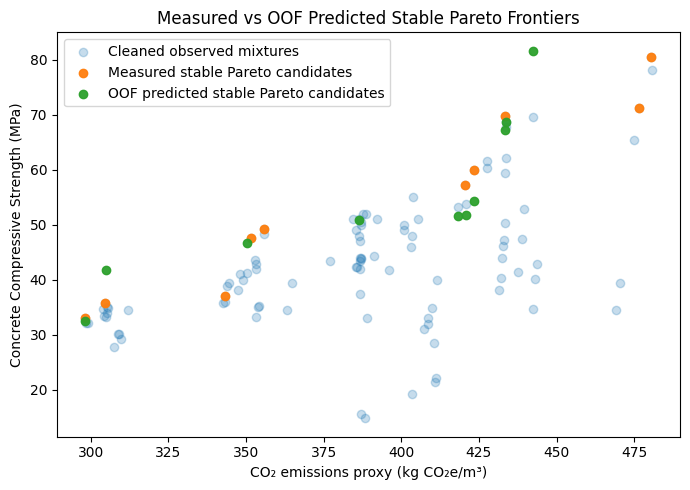

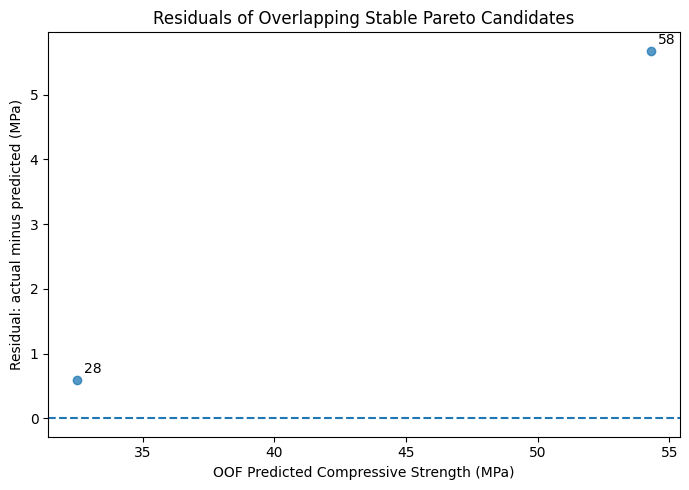

Saved: /content/figures/stable_pareto_residual_plot_rca.png


,source_row_number,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate,recycled_aggregate_fraction,compressive_strength_mpa,oof_predicted_strength_mpa,residual_mpa,absolute_prediction_error_mpa,co2_proxy_low_kg_per_m3,co2_proxy_central_kg_per_m3,co2_proxy_high_kg_per_m3
26,28,300.0,150.0,734.0,657.000000,202.450000,550.0,0.351046,33.1,32.506823,0.593177,0.593177,267.171620,298.273005,373.007245
55,58,425.0,185.0,696.0,962.333333,199.646667,1028.0,0.425383,60.0,54.318974,5.681026,5.681026,378.084997,423.517562,524.770855


Saved: /content/outputs/stable_pareto_residual_table_rca.csv


In [20]:
# Calculates the emissions proxy in Numpy
# Returns results to pandas Series; results ready to be saved
def calculate_emissions_proxy(
    frame,
    scenario_factors,
):
    factor_series = (
        scenario_factors
        .set_index("material")[
            "co2_kg_per_kg"
        ]
    )

    total = np.zeros(
        len(frame),
        dtype=float,
    )

    for material in required_materials:
        total += (
            frame[material]
            .to_numpy(dtype=float)
            * float(
                factor_series.loc[
                    material
                ]
            )
        )

    return pd.Series(
        total,
        index=frame.index,
    )

# Used to minimize emissions while maximizing strength
# Removes dominated mixes (non-Pareto optimal)
def nondominated_emissions_strength(
    emissions,
    strengths,
):
    keep = np.ones(
        len(strengths),
        dtype=bool,
    )

    for index in range(len(strengths)):
        dominates_index = (
            (emissions <= emissions[index])
            & (strengths >= strengths[index])
            & (
                (emissions < emissions[index])
                | (
                    strengths
                    > strengths[index]
                )
            )
        )

        if dominates_index.any():
            keep[index] = False

    return keep

# Initialize an empty list
scenario_results = []

# Searches for emission scenarios before grouping them
for scenario_name in [
    "low",
    "central",
    "high",
]:
    # Selects a single emission scenario and only selects factors based on that value
    # Done to check if Pareto-optimal mixtures hold up across all 3 scenarios
    scenario_factors = factor_scenarios[
        factor_scenarios[
            "scenario"
        ]
        == scenario_name
    ]

    # Defines a variable before computing CO2 emissions
    emissions_column = (
        f"co2_proxy_{scenario_name}_"
        "kg_per_m3"
    )

    # Adds estimated emissions for each mixture to the DataFrame
    # Labeled differently based on the emission scenario
    candidate_df[
        emissions_column
    ] = calculate_emissions_proxy(
        candidate_df,
        scenario_factors,
    )

    # Identifies the Pareto-optimal mixtures in the DataFrame
    # Checks for lower emissions and higher predicted strength

    # Pareto frontier using OOF predicted strength
    candidate_df[
        f"is_pareto_predicted_{scenario_name}"
        ] = (
        nondominated_emissions_strength(
            candidate_df[
                emissions_column
            ].to_numpy(),
            candidate_df[
                "oof_predicted_strength_mpa"
            ].to_numpy(),
        )
    )

    # Pareto frontier using measured strength
    candidate_df[
        f"is_pareto_measured_{scenario_name}"
        ] = (
        nondominated_emissions_strength(
            candidate_df[
                emissions_column
            ].to_numpy(),
            candidate_df[
                TARGET_COL
            ].to_numpy(),
        )
    )



    # Stores the Pareto candidates for future outputs
    scenario_results.append(
        {
            "scenario": scenario_name,
            "predicted_pareto_candidate_count": int(
                candidate_df[
                    f"is_pareto_predicted_{scenario_name}"
                ].sum()
            ),
            "measured_pareto_candidate_count": int(
                candidate_df[
                    f"is_pareto_measured_{scenario_name}"
                ].sum()
            ),
            "total_mixtures": len(candidate_df),
        }
    )

# Checks if the mixture stays Pareto-optimal across all 3 scenarios
# Assigns a numeric value from 1-3 based on how many scenarios the mixture was non-dominated

# Counts how many scenarios each mixture is Pareto-optimal for predicted strength
candidate_df[
    "predicted_pareto_selection_count"
] = (
    candidate_df[
        [
            "is_pareto_predicted_low",
            "is_pareto_predicted_central",
            "is_pareto_predicted_high",
        ]
    ]
    .sum(axis=1)
)

# Counts how many scenarios each mixture is Pareto-optimal for measured strength
candidate_df[
    "measured_pareto_selection_count"
] = (
    candidate_df[
        [
            "is_pareto_measured_low",
            "is_pareto_measured_central",
            "is_pareto_measured_high",
        ]
    ]
    .sum(axis=1)
)

# Calculates absolute prediction error and difference between measured and predicted strength
candidate_df[
    "strength_prediction_difference_mpa"
] = (
    candidate_df[TARGET_COL] - candidate_df["oof_predicted_strength_mpa"]
)

candidate_df[
    "absolute_prediction_error_mpa"
] = (
    candidate_df["strength_prediction_difference_mpa"].abs()
)

# Determines if a non-dominated mixture is "stable"
# Uses different pareto_selection_count variables as the main way of determining this information
# Extracts Pareto-optimal mixtures before ranking them
predicted_stable_pareto_candidates = (
    candidate_df[
        candidate_df[
            "predicted_pareto_selection_count"
        ] == 3
    ]
    .sort_values(
        [
            "co2_proxy_central_kg_per_m3",
            "oof_predicted_strength_mpa",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


measured_stable_pareto_candidates = (
    candidate_df[
        candidate_df[
            "measured_pareto_selection_count"
        ] == 3
    ]
    .sort_values(
        [
            "co2_proxy_central_kg_per_m3",
            TARGET_COL,
        ],
        ascending=[
            True,
            False,
        ],
    )
)

# Defines source_row_number to identify intersections between OOF predicted
# and measured Pareto candidates
measured_stable_ids = set(
    measured_stable_pareto_candidates[
        "source_row_number"
    ]
)

predicted_stable_ids = set(
    predicted_stable_pareto_candidates[
        "source_row_number"
    ]
)

# Finds the intersections for stable candidates
stable_overlap_ids = (
    measured_stable_ids
    & predicted_stable_ids
)

stable_overlap_count = len(
    stable_overlap_ids
)

print(
    "Stable Pareto candidates in both measured and OOF predicted:",
    stable_overlap_count,
)

# Creates a DataFrame with the results
stable_overlap_candidates = (
    candidate_df[
        candidate_df[
            "source_row_number"
        ].isin(stable_overlap_ids)
    ]
    .sort_values(
        "source_row_number"
    )
)

# Creates a summary of the number of Pareto-optimal mixtures
pareto_scenario_summary = pd.DataFrame(
    scenario_results
)

# Results are saved to publication-ready outputs and figures further in the code
# Defines file paths
all_candidate_path = (
    OUT_DIR
    / "rca_sustainability_and_pareto_sensitivity_rca.csv"
)

stable_pareto_path = (
    OUT_DIR
    / "stable_pareto_candidates_rca.csv"
)

pareto_summary_path = (
    OUT_DIR
    / "pareto_scenario_summary_rca.csv"
)

pareto_count_summary_path = (
    OUT_DIR
    / "pareto_candidate_count_summary_rca.csv"
)

# Saves Pareto candidates, stable Pareto candidates, and a scenario summary
    # Pareto candidates -> total non-dominated mixtures in DataFrame
    # Stable Pareto candidates -> non-dominated mixtures across all 3 scenarios
        # Split between OOF prediction and measured Pareto frontiers
    # Scenario summary -> number of non-dominated mixtures in each scenario
candidate_df.to_csv(
    all_candidate_path,
    index=False,
)

predicted_stable_pareto_candidates.to_csv(
    OUT_DIR / "predicted_stable_pareto_candidates_rca.csv",
    index=False,
)

measured_stable_pareto_candidates.to_csv(
    OUT_DIR / "measured_stable_pareto_candidates_rca.csv",
    index=False,
)

pareto_scenario_summary.to_csv(
    pareto_summary_path,
    index=False,
)

print("Saved:", all_candidate_path)
print("Saved:",
    OUT_DIR / "predicted_stable_pareto_candidates_rca.csv"
)
print("Saved:",
    OUT_DIR / "measured_stable_pareto_candidates_rca.csv"
)
print("Saved:",
    pareto_summary_path)

print("Saved:",
    pareto_count_summary_path
)

display(pareto_scenario_summary)

# Displays amount of Pareto candidates and stable Pareto candidates
# Represents each frontier separately and compends results into a table
measured = candidate_df["measured_pareto_selection_count"].gt(0)
predicted = candidate_df["predicted_pareto_selection_count"].gt(0)

pareto_count_summary = pd.DataFrame(
    {
        "Category": [
            "Total unique Pareto candidates",
            "Total measured Pareto candidates",
            "Total OOF predicted Pareto candidates",
            "OOF predicted stable Pareto candidates",
            "Measured stable Pareto candidates",
            "Stable candidates in both measured and OOF predicted",
        ],
        "Count": [
            int((measured | predicted).sum()),
            int(measured.sum()),
            int(predicted.sum()),
            len(predicted_stable_pareto_candidates),
            len(measured_stable_pareto_candidates),
            stable_overlap_count,
        ],
    }
)

pareto_count_summary.to_csv(
    pareto_count_summary_path,
    index=False,
)

display(
    pareto_count_summary
)

# Used as a tabular version of the code results for the user
# Shows each Pareto frontier as separate tables
display(
    measured_stable_pareto_candidates[
        [
            "source_row_number",
            "cement",
            "water",
            "natural_fine_aggregate",
            "natural_coarse_aggregate",
            "recycled_fine_aggregate",
            "recycled_coarse_aggregate",
            "recycled_aggregate_fraction",
            TARGET_COL,
            "oof_predicted_strength_mpa",
            "strength_prediction_difference_mpa",
            "absolute_prediction_error_mpa",
            "co2_proxy_low_kg_per_m3",
            "co2_proxy_central_kg_per_m3",
            "co2_proxy_high_kg_per_m3",
        ]
    ]
)

display(
    predicted_stable_pareto_candidates[
        [
            "source_row_number",
            "cement",
            "water",
            "natural_fine_aggregate",
            "natural_coarse_aggregate",
            "recycled_fine_aggregate",
            "recycled_coarse_aggregate",
            "recycled_aggregate_fraction",
            TARGET_COL,
            "oof_predicted_strength_mpa",
            "strength_prediction_difference_mpa",
            "absolute_prediction_error_mpa",
            "co2_proxy_low_kg_per_m3",
            "co2_proxy_central_kg_per_m3",
            "co2_proxy_high_kg_per_m3",
        ]
    ]
)

display(
    stable_overlap_candidates[
        [
            "source_row_number",
            "cement",
            "water",
            "natural_fine_aggregate",
            "natural_coarse_aggregate",
            "recycled_fine_aggregate",
            "recycled_coarse_aggregate",
            "recycled_aggregate_fraction",
            TARGET_COL,
            "oof_predicted_strength_mpa",
            "strength_prediction_difference_mpa",
            "absolute_prediction_error_mpa",
            "co2_proxy_low_kg_per_m3",
            "co2_proxy_central_kg_per_m3",
            "co2_proxy_high_kg_per_m3",
        ]
    ]
)

print("Measured-strength stable Pareto candidates")
print("OOF-predicted-strength stable Pareto candidates")

# ============================================================
# Stable Pareto Frontier Scatterplot
# ============================================================
# Displays the Pareto-optimal solutions on the tradeoff graph
# Plots on same graph for easier candidate comparison
# Saves figure for publication
fig, ax = plt.subplots(figsize=(7, 5))

# Plots mixtures across all scenarios
ax.scatter(
    candidate_df["co2_proxy_central_kg_per_m3"],
    candidate_df[TARGET_COL],
    alpha=0.25,
    label="Cleaned observed mixtures",
)

# Measured Pareto frontier
ax.scatter(
    measured_stable_pareto_candidates[
        "co2_proxy_central_kg_per_m3"
    ],
    measured_stable_pareto_candidates[
        TARGET_COL
    ],
    alpha=0.95,
    label="Measured stable Pareto candidates",
)

# OOF predicted Pareto frontier
ax.scatter(
    predicted_stable_pareto_candidates[
        "co2_proxy_central_kg_per_m3"
    ],
    predicted_stable_pareto_candidates[
        "oof_predicted_strength_mpa"
    ],
    alpha=0.95,
    label="OOF predicted stable Pareto candidates",
)

ax.legend()

ax.set_xlabel(
    "CO₂ emissions proxy (kg CO₂e/m³)"
)

ax.set_ylabel(
    "Concrete Compressive Strength (MPa)"
)

ax.set_title(
    "Measured vs OOF Predicted Stable Pareto Frontiers"
)


fig.tight_layout()

fig_path = (
    FIG_DIR
    / "measured_vs_predicted_stable_pareto_frontiers_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

print("Saved:", fig_path)

plt.show()

# ============================================================
# Stable Pareto Frontier Residual Scatterplot
# ============================================================
# Residuals graph (Negative = Overpredicted, Positive = Underpredicted)
# Provides another way to graph model accuracy
# Saved to figures for publication

# Selects stable Pareto candidates from both frontiers
residual_candidates = (
    candidate_df[
        candidate_df["source_row_number"].isin(
            stable_overlap_ids
        )
    ]
    .copy()
    .sort_values("source_row_number")
)

# Calculate residual for each candidate
residual_candidates[
    "residual_mpa"
] = (
    residual_candidates[TARGET_COL]
    - residual_candidates["oof_predicted_strength_mpa"]
)

# Plots residual scatterplot
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    residual_candidates[
        "oof_predicted_strength_mpa"
    ],
    residual_candidates[
        "residual_mpa"
    ],
    alpha=0.75,
)

# Identifies source_row_number for each point
# Helpful in identifying certain points on the residual data table
for _, row in residual_candidates.iterrows():
    ax.annotate(
        str(int(row["source_row_number"])),
        (
            row["oof_predicted_strength_mpa"],
            row["residual_mpa"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )

# Reference line
ax.axhline(
    0,
    linestyle="--",
)


ax.set_xlabel(
    "OOF Predicted Compressive Strength (MPa)"
)

ax.set_ylabel(
    "Residual: actual minus predicted (MPa)"
)

ax.set_title(
    "Residuals of Overlapping Stable Pareto Candidates"
)

fig.tight_layout()

residual_fig_path = (
    FIG_DIR
    / "stable_pareto_residual_plot_rca.png"
)

fig.savefig(
    residual_fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", residual_fig_path)

# ============================================================
# Residual plot table
# ============================================================
# Contains every plotted point to compare prediction errors

residual_table = residual_candidates[
    [
        "source_row_number",
        "cement",
        "water",
        "natural_fine_aggregate",
        "natural_coarse_aggregate",
        "recycled_fine_aggregate",
        "recycled_coarse_aggregate",
        "recycled_aggregate_fraction",
        TARGET_COL,
        "oof_predicted_strength_mpa",
        "residual_mpa",
        "absolute_prediction_error_mpa",
        "co2_proxy_low_kg_per_m3",
        "co2_proxy_central_kg_per_m3",
        "co2_proxy_high_kg_per_m3",
    ]
].copy()

# Displays and saves table for publication
display(
    residual_table
)

residual_table_path = (
    OUT_DIR
    / "stable_pareto_residual_table_rca.csv"
)

residual_table.to_csv(
    residual_table_path,
    index=False,
)

print("Saved:", residual_table_path)


**Measured and Predicted Stable Pareto Frontiers Scatterplot:** The figure plots stable Pareto candidates based on measured compressive strength and OOF predicted compressive strength. The predicted candidates are closely correlated with the measured Pareto candidates, indicating minimal variation between the candidates within the context of the emissions proxy analysis. Measured and predicted frontiers overlap for some candidate mixtures but diverge for others, indicating that model-based candidate selection is not identical to selection using measured strength.

**Stable Pareto Frontier Residual Scatterplot:** The predicted and measured frontiers share two stable candidates, while most stable candidates differ between the two frontiers. Additionally, the residual plot serves only as a descriptive visualization of overlapping stable Pareto candidates. Therefore, model-based Pareto candidate identification should be treated as exploratory rather than as a direct reproduction of the measured frontier.

In [21]:
# Contains a list of stable non-dominated mixtures for minimum predicted strength values
    # Currently only considers OOF predicted stable Pareto candidates
# Prefer candidates stable across all scenarios
# If no stable candidates exist at a threshold:
    # Use the central-scenario Pareto set
    # Label the reduced stability

# Creates a DataFrame with only Pareto-optimal mixtures
central_predicted_pareto = candidate_df[
    candidate_df[
        "is_pareto_predicted_central"
    ]
].copy()

# Initialize an empty list
threshold_rows = []

# Sets the minimum predicted concrete compressive strength for each mixture
# Loops over these thresholds when looking over DataFrame
for threshold in [
    30,
    40,
    50,
    60,
]:
    # Finds stable Pareto candidates that meet the strength threshold
    # Applies this to both measured and predicted compressive strength
    stable_eligible = predicted_stable_pareto_candidates[
        (predicted_stable_pareto_candidates[
            "oof_predicted_strength_mpa"
        ] >= threshold)
        &
        (predicted_stable_pareto_candidates[
            TARGET_COL
        ] >= threshold)
    ]

    if len(stable_eligible) > 0:
        eligible = stable_eligible
        stability_label = (
            "stable across low, central, and high scenarios"
        )

    # Fallback if stable candidates do not exist
    else:
        eligible = central_predicted_pareto[
            (central_predicted_pareto[
                "oof_predicted_strength_mpa"
            ]
            >= threshold)
        &
        (central_predicted_pareto[
            TARGET_COL
        ] >= threshold)
    ]
        stability_label = (
            "central-predicted-scenario Pareto only"
        )

    # Only runs when no Pareto-optimal candidates exist for a given strength threshold
    if len(eligible) == 0:
        threshold_rows.append(
            {
                "minimum_oof_predicted_strength_mpa": threshold,
                "available": False,
                "stability": "no candidate",
            }
        )

    # Ensures that eligible mixtures are chosen
    else:
        best = eligible.sort_values(
            "co2_proxy_central_kg_per_m3"
        ).iloc[0]

        # Records all relevant information for tabling
        threshold_rows.append(
            {
                "minimum_oof_predicted_strength_mpa": threshold,
                "available": True,
                "stability": stability_label,
                "source_row_number": best[
                    "source_row_number"
                ],
                "measured_strength_mpa": best[
                    TARGET_COL
                ],
                "oof_predicted_strength_mpa": best[
                    "oof_predicted_strength_mpa"
                ],
                "central_co2_proxy_kg_per_m3": best[
                    "co2_proxy_central_kg_per_m3"
                ],
                "recycled_aggregate_fraction": best[
                    "recycled_aggregate_fraction"
                ],
                "cement": best["cement"],
                "water": best["water"],
                "natural_fine_aggregate": best[
                    "natural_fine_aggregate"
                ],
                "natural_coarse_aggregate": best[
                    "natural_coarse_aggregate"
                ],
                "recycled_fine_aggregate": best[
                    "recycled_fine_aggregate"
                ],
                "recycled_coarse_aggregate": best[
                    "recycled_coarse_aggregate"
                ],
            }
        )

# Creates and saves a table for stable Pareto-optimal mixtures
# Important output for sustainability analysis section of the notebook
threshold_df = pd.DataFrame(
    threshold_rows
)

threshold_path = (
    OUT_DIR
    / "pareto_strength_threshold_shortlist_rca.csv"
)

threshold_df.to_csv(
    threshold_path,
    index=False,
)

# Prints for user manual review
print("Saved:", threshold_path)
display(threshold_df)

Saved: /content/outputs/pareto_strength_threshold_shortlist_rca.csv


,minimum_oof_predicted_strength_mpa,available,stability,source_row_number,measured_strength_mpa,oof_predicted_strength_mpa,central_co2_proxy_kg_per_m3,recycled_aggregate_fraction,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate
0,30,True,"stable across low, central, and high scenarios",28,33.1,32.506823,298.273005,0.351046,300.0,150.0,734.0,657.0,202.450000,550.000000
1,40,True,"stable across low, central, and high scenarios",6,41.2,46.724490,350.461040,0.220859,350.0,140.0,728.0,1304.0,214.333333,361.666667
2,50,True,"stable across low, central, and high scenarios",60,53.2,51.583618,418.322895,0.468044,425.0,185.0,696.0,647.0,199.646667,982.000000
3,60,True,"stable across low, central, and high scenarios",74,62.1,68.642586,433.811190,0.491707,440.0,155.0,666.0,670.0,198.403333,1094.000000


**Result Interpretation:** This section of the code presents the lowest emissions mixture given a minimum predicted concrete strength requirement. The table presents 4 different mixtures generated from the emissions proxy.

## 17. Final synthesis and limitations

The final conclusions must explicitly state:

- how many rows were flagged and excluded;
- whether the aggregate-cement ratio passed its consistency audit;
- which feature set was selected;
- the primary held-out metrics;
- the distribution of metrics across repeated grouped validation;
- the high-strength subgroup error;
- how many Pareto candidates remained stable across factor scenarios;
- that the emissions analysis is a proxy rather than a full LCA;
- that external validation is not available.

In [22]:
# Purely text-based portion of the code to record the results of the notebook
repeated_metric_lookup = (
    repeated_summary_df
    .set_index("metric")
)

high_strength_rows = (
    error_by_strength_band[
        error_by_strength_band[
            "strength_band_mpa"
        ].astype(str)
        == "Q4 (highest strength)"
    ]
)

if len(high_strength_rows) == 1:
    high_strength_count = int(
        high_strength_rows.iloc[0][
            "count"
        ]
    )
    high_strength_mae = float(
        high_strength_rows.iloc[0][
            "mean"
        ]
    )
else:
    high_strength_count = 0
    high_strength_mae = np.nan

synthesis = {
    "dataset_rows_raw": int(
        len(raw_df)
    ),
    "documented_corrections_applied": int(
        len(correction_log_df)
    ),
    "flagged_rows_excluded": int(
        len(flagged_rows)
    ),
    "cleaned_rows_modeled": int(
        len(model_df)
    ),
    "aggregate_ratio_consistency_rate": (
        aggregate_ratio_consistency_rate
    ),
    "aggregate_ratio_verified": (
        aggregate_ratio_verified
    ),
    "selected_feature_set": (
        selected_feature_set_name
    ),
    "selected_features": (
        selected_features
    ),
    "selected_model": (
        selected_name
    ),
    "primary_holdout_metrics": (
        final_metrics
    ),
    "nested_grouped_oof_metrics": (
        oof_metrics
    ),
    "repeated_group_validation_median": {
        metric: float(
            repeated_metric_lookup.loc[
                metric,
                "median",
            ]
        )
        for metric in [
            "r2",
            "mae_mpa",
            "rmse_mpa",
        ]
    },
    "repeated_group_validation_2_5_to_97_5": {
        metric: [
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "range_2_5",
                ]
            ),
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "range_97_5",
                ]
            ),
        ]
        for metric in [
            "r2",
            "mae_mpa",
            "rmse_mpa",
        ]
    },
    "repeated_group_validation_iqr": {
        metric: [
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "iqr_25",
                ]
            ),
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "iqr_75",
                ]
            ),
        ]
        for metric in [
            "r2",
            "mae_mpa",
            "rmse_mpa",
        ]
    },
    "repeated_group_validation_min_max": {
        metric: [
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "minimum",
                ]
            ),
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "maximum",
                ]
            ),
        ]
        for metric in [
            "r2",
            "mae_mpa",
            "rmse_mpa",
        ]
    },
    "high_strength_test_quartile": {
        "threshold": "Q4 (highest strength)",
        "count": high_strength_count,
        "mean_absolute_error_mpa": (
            high_strength_mae
        ),
    },
    "stable_pareto_candidate_count": int(
        len(predicted_stable_pareto_candidates)
    ),
    "external_validation_available": False,
}

synthesis_json_path = (
    OUT_DIR
    / "notebook3_final_synthesis_rca.json"
)

with open(
    synthesis_json_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        synthesis,
        file,
        indent=2,
    )

synthesis_lines = [
    "# Notebook 3 RCA final synthesis",
    "",
    (
        f"Dataset: {RCA_DATASET_AUTHOR} "
        f"({RCA_DATASET_YEAR}), "
        f"{RCA_DATASET_TITLE}, "
        f"DOI {RCA_DATASET_DOI}."
    ),
    "",
    "Data audit:",
    (
        f"- Raw rows: {len(raw_df)}"
    ),
    (
        "- Documented corrections applied: "
        f"{len(correction_log_df)}"
    ),
    (
        "- Physically implausible rows excluded "
        f"after being saved for review: {len(flagged_rows)}"
    ),
    (
        f"- Cleaned rows modeled: {len(model_df)}"
    ),
    (
        "- Aggregate-cement ratio consistency rate: "
        f"{aggregate_ratio_consistency_rate:.3f}"
    ),
    (
        "- Aggregate-cement ratio treated as a "
        f"verified feature: {aggregate_ratio_verified}"
    ),
    "",
    "Modeling:",
    (
        "- Selected feature set from training-only "
        f"grouped CV: {selected_feature_set_name}"
    ),
    (
        f"- Selected model: {selected_name}"
    ),
    (
        "- Primary grouped hold-out R²: "
        f"{final_metrics['r2']:.3f}"
    ),
    (
        "- Primary grouped hold-out MAE: "
        f"{final_metrics['mae_mpa']:.3f} MPa"
    ),
    (
        "- Primary grouped hold-out RMSE: "
        f"{final_metrics['rmse_mpa']:.3f} MPa"
    ),
    "",
        "Nested grouped out-of-fold prediction:",
    (
        "- OOF R²: "
        f"{oof_metrics['r2']:.3f}"
    ),
    (
        "- OOF MAE: "
        f"{oof_metrics['mae_mpa']:.3f} MPa"
    ),
    (
        "- OOF RMSE: "
        f"{oof_metrics['rmse_mpa']:.3f} MPa"
    ),
    "",
    "Repeated nested grouped validation:",
    (
        "- Median R²: "
        f"{repeated_metric_lookup.loc['r2', 'median']:.3f}"
    ),
    (
        "- R² range across outer splits: "
        f"{repeated_metric_lookup.loc['r2', 'minimum']:.3f}–"
        f"{repeated_metric_lookup.loc['r2', 'maximum']:.3f}"
    ),
    (
        "- Median MAE: "
        f"{repeated_metric_lookup.loc['mae_mpa', 'median']:.3f} MPa"
    ),
    (
        "- MAE range across outer splits: "
        f"{repeated_metric_lookup.loc['mae_mpa', 'minimum']:.3f}–"
        f"{repeated_metric_lookup.loc['mae_mpa', 'maximum']:.3f} MPa"
    ),
    (
        "- Median RMSE: "
        f"{repeated_metric_lookup.loc['rmse_mpa', 'median']:.3f} MPa"
    ),
    (
        "- RMSE range across outer splits: "
        f"{repeated_metric_lookup.loc['rmse_mpa', 'minimum']:.3f}–"
        f"{repeated_metric_lookup.loc['rmse_mpa', 'maximum']:.3f} MPa"
    ),
    "",
    "Held-out test-set error analysis:",
    (
        "- Highest-strength quartile "
        "(Q4) count: "
        f"{high_strength_count}"
    ),
    (
        "- Highest-strength quartile "
        "(Q4) mean absolute error: "
        f"{high_strength_mae:.3f} MPa"
    ),
    "Sustainability and Pareto analysis:",
    (
        "- Stable predicted Pareto candidates across all "
        f"three factor scenarios: {len(predicted_stable_pareto_candidates)}"
    ),
    (
        "- The proxy is not a complete life-cycle assessment."
    ),
    (
        "- Candidate mixtures are observed nondominated "
        "examples, not globally optimized recipes."
    ),
    "",
    "Recommended conclusion:",
    (
        "The RCA dataset extends the baseline SCM modeling "
        "architecture by adding recycled coarse and fine "
        "aggregate variables. The strongest conclusions are "
        "the reproducible group-aware prediction results and "
        "the sensitivity-tested identification of observed "
        "strength-emissions tradeoffs. Claims about universal "
        "RCA effects, exact life-cycle emissions, or optimal "
        "mixture design are not supported without independent "
        "external validation and experimentally controlled data."
    ),
]

synthesis_text = "\n".join(
    synthesis_lines
)

synthesis_markdown_path = (
    OUT_DIR
    / "notebook3_final_synthesis_rca.md"
)

with open(
    synthesis_markdown_path,
    "w",
    encoding="utf-8",
) as file:
    file.write(synthesis_text)

print("Saved:", synthesis_json_path)
print("Saved:", synthesis_markdown_path)
print(synthesis_text)

Saved: /content/outputs/notebook3_final_synthesis_rca.json
Saved: /content/outputs/notebook3_final_synthesis_rca.md
# Notebook 3 RCA final synthesis

Dataset: Paul Awoyera (2025), Mechanical Properties of Recycled Aggregate Concrete, DOI 10.17632/2pxdbh6vx7.1.

Data audit:
- Raw rows: 112
- Documented corrections applied: 0
- Physically implausible rows excluded after being saved for review: 0
- Cleaned rows modeled: 104
- Aggregate-cement ratio consistency rate: 0.163
- Aggregate-cement ratio treated as a verified feature: False

Modeling:
- Selected feature set from training-only grouped CV: full_engineered
- Selected model: RandomForest_tuned
- Primary grouped hold-out R²: 0.675
- Primary grouped hold-out MAE: 4.463 MPa
- Primary grouped hold-out RMSE: 6.945 MPa

Nested grouped out-of-fold prediction:
- OOF R²: 0.767
- OOF MAE: 4.569 MPa
- OOF RMSE: 5.972 MPa

Repeated nested grouped validation:
- Median R²: 0.806
- R² range across outer splits: 0.624–0.928
- Median MAE: 4.093 MPa
-

## 18. Reproducibility manifest

In [23]:
# Purely text-based portion of the code to record the results of the notebook
def file_sha256(path):
    hash_object = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(8192),
            b"",
        ):
            hash_object.update(chunk)

    return hash_object.hexdigest()


manifest = {
    "notebook": (
        "03_rca_dataset_modeling_and_"
        "pareto_analysis.ipynb"
    ),
    "run_mode": RUN_MODE,
    "base_dir": str(BASE_DIR),
    "dataset": {
        "title": RCA_DATASET_TITLE,
        "author": RCA_DATASET_AUTHOR,
        "year": RCA_DATASET_YEAR,
        "doi": RCA_DATASET_DOI,
        "local_file": str(rca_path),
        "sha256": file_sha256(rca_path),
    },
    "random_state": RANDOM_STATE,
    "flagged_row_policy": (
        FLAGGED_ROW_POLICY
    ),
    "documented_corrections_applied": int(
        len(correction_log_df)
    ),
    "flagged_rows_excluded": int(
        len(flagged_rows)
    ),
    "aggregate_ratio_verified": (
        aggregate_ratio_verified
    ),
    "selected_feature_set": (
        selected_feature_set_name
    ),
    "selected_features": (
        selected_features
    ),
    "selected_model": selected_name,
    "primary_holdout_metrics": (
        final_metrics
    ),
    "repeated_group_splits": (
        N_REPEATED_GROUP_SPLITS
    ),
    "stable_predicted_pareto_candidate_count": int(
        len(predicted_stable_pareto_candidates)
    ),
    "outputs_created": sorted(
        path.name
        for path in OUT_DIR.glob(
            "*rca*"
        )
    ),
    "figures_created": sorted(
        path.name
        for path in FIG_DIR.glob(
            "*rca*.png"
        )
    ),
    "package_versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": (
            plt.matplotlib.__version__
        ),
        "scikit_learn": (
            sklearn.__version__
        ),
        "openpyxl": (
            openpyxl.__version__
        ),
    },
}

manifest_path = (
    OUT_DIR
    / "notebook3_reproducibility_manifest_rca.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        indent=2,
    )

print("Saved:", manifest_path)
display(manifest)

Saved: /content/outputs/notebook3_reproducibility_manifest_rca.json


{'notebook': '03_rca_dataset_modeling_and_pareto_analysis.ipynb',
 'run_mode': 'repo',
 'base_dir': '/content',
 'dataset': {'title': 'Mechanical Properties of Recycled Aggregate Concrete',
  'author': 'Paul Awoyera',
  'year': '2025',
  'doi': '10.17632/2pxdbh6vx7.1',
  'local_file': '/content/data/rca_awoyera_2025_mechanical_properties.xlsx',
  'sha256': '49c2885a300ba96ed7f7c6a865180ad9a34d9a8be1714c44c7b9ab31121b5678'},
 'random_state': 42,
 'flagged_row_policy': 'exclude',
 'documented_corrections_applied': 0,
 'flagged_rows_excluded': 0,
 'aggregate_ratio_verified': False,
 'selected_feature_set': 'full_engineered',
 'selected_features': ['water_cement_ratio',
  'water',
  'aggregate_cement_ratio',
  'cement',
  'natural_fine_aggregate',
  'natural_coarse_aggregate',
  'recycled_coarse_aggregate',
  'recycled_fine_aggregate',
  'total_natural_aggregate',
  'total_recycled_aggregate',
  'total_fine_aggregate',
  'total_coarse_aggregate',
  'total_aggregate',
  'recycled_aggregate_

## 19. Download relevant files

This section downloads the data, figures, and output files as ZIP files. If the files are already saved, this code can be skipped.

In [24]:
from google.colab import files

# Zips all relevant folders
os.system("zip -r data.zip data")
os.system("zip -r outputs.zip outputs")
os.system("zip -r figures.zip figures")

# Download the zip file
files.download("data.zip")
files.download("outputs.zip")
files.download("figures.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>